# Screening Water Samples for Potability: A Baseline-Driven Classification Study

ES 335 (undergraduate pair project), IIT Gandhinagar. Random seed 42 everywhere.

> **Overview.** We compare logistic regression, a decision tree and a random forest against a majority-class baseline in three feature scenarios (A, B, C). Model settings, class weights, missing-value indicators and decision thresholds are all chosen with 5-fold cross-validation on the training part only; the held-out test set scores the final models once. Extra experiments: (1) random-forest hyperparameter tuning, (2) class weights, (3) classification threshold, (4) missing-value indicators, (5) precision-recall curves.

## 1. Problem, why these metrics, and claim limits

**Research question.** Using the measured physicochemical parameters in the Water Potability dataset, how well can ML models predict the *recorded* potability label, and how does performance change across three hypothetical feature-availability scenarios, compared with a majority-class baseline?

**Why a baseline.** About 61% of the samples are labelled non-potable. A "model" that always answers *non-potable* is therefore right about 61% of the time without looking at any measurement. Every real model must be judged against that.

**Why these metrics.** A *false "potable"* (a non-potable sample predicted potable) is the costlier error, because it would let a bad sample through. So we report:

- **recall (non-potable)**: of the truly non-potable samples, what share did we flag?
- **share of "potable" calls that are actually non-potable** (= 1 minus precision for potable): when the model says "potable", how often is it wrong in the costly way?

**Recall alone is misleading.** The majority baseline gets 100% non-potable recall by always predicting non-potable, yet it never clears a single potable sample and has no skill. So recall is always read together with precision, balanced accuracy and average precision, and always next to the baseline. Accuracy is not a headline metric (a small secondary table only).

**Scenarios** (experimental feature subsets, *not* validated testing procedures; the A/B grouping is our assumption, not a property of the data):

| Scenario | Name | Features |
|---|---|---|
| A | Quick on-site check | ph, Conductivity, Turbidity |
| B | Basic test kit | A + Solids, Hardness, Chloramines (6 features) |
| C | Full panel | all 9 features (adds Sulfate, Organic_carbon, Trihalomethanes) |

**Claim limits.** We predict the *recorded label* in one public dataset. We do **not** claim that a sample predicted "potable" is safe to drink (the data has no microbial or heavy-metal measurements, and the origin of the label is unclear). Results show association, not cause, and must not be generalised to Indian rivers or any specific region.

In [1]:
import os, sys, json, math, warnings, datetime, platform
from pathlib import Path
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)
SHOW_RAW_ROWS = True      # set to False to hide raw dataset rows (e.g. if the dataset licence requires it)
N_BOOT = 2000

# Find the repo root whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd()
if not (ROOT / "notebooks").exists() and (ROOT.parent / "notebooks").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "water_potability.csv"
ASSETS = ROOT / "docs" / "assets"
RESULTS_PATH = ROOT / "docs" / "results.json"
ASSETS.mkdir(parents=True, exist_ok=True)

# Colour-blind-safe palette (Okabe-Ito)
C_NONPOT, C_POT, C_BASE = "#D55E00", "#0072B2", "#6B6B6B"
C_SCEN = {"A": "#0072B2", "B": "#E69F00", "C": "#009E73"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save_fig(fig, name):
    path = ASSETS / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except Exception:
        pass
    return path


print("Repo root:", ROOT)

Repo root: /home/claude


## 2. Data loading and quality checks

**Why:** before modelling we confirm the file is exactly the dataset we think it is. Every expected number is checked with an assertion; if one fails, the notebook stops instead of silently continuing on different data. The class-balance and missingness checks also tell us *why* the baseline is strong and *why* imputation must be done carefully.

The distribution plots and group means below describe the whole file for orientation only. No modelling choice (features, grids, scorer, scenarios, threshold rule) was made from them; all of those were fixed in advance.

In [2]:
KAGGLE_URL = "https://www.kaggle.com/datasets/adityakadiwal/water-potability"
if not DATA_PATH.exists():
    msg = (f"Data file not found: {DATA_PATH}\n"
           f"Download water_potability.csv from {KAGGLE_URL}\n"
           f"(check the dataset licence on that page) and place it at data/water_potability.csv, then re-run.")
    print(msg)
    raise FileNotFoundError(msg)

FEATURES = ["ph", "Hardness", "Solids", "Chloramines", "Sulfate", "Conductivity",
            "Organic_carbon", "Trihalomethanes", "Turbidity"]
TARGET = "Potability"
df = pd.read_csv(DATA_PATH)

print("shape:", df.shape)
print(df.dtypes.to_string())

shape: (3276, 10)
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64


In [3]:
# ---- Data assertions (stop if any fails) ----
assert df.shape == (3276, 10), df.shape
assert set(df.columns) == set(FEATURES + [TARGET])
vc = df[TARGET].value_counts()
assert vc[0] == 1998 and vc[1] == 1278, vc.to_dict()
assert round(100 * vc[0] / len(df), 2) == 60.99 and round(100 * vc[1] / len(df), 2) == 39.01
miss = df.isna().sum()
assert miss["ph"] == 491 and miss["Sulfate"] == 781 and miss["Trihalomethanes"] == 162, miss.to_dict()
assert miss.drop(["ph", "Sulfate", "Trihalomethanes"]).sum() == 0
assert df.duplicated().sum() == 0
print("All data assertions passed.")
print("\nmissing values per column:\n", miss.to_string())
print("\nduplicate rows:", int(df.duplicated().sum()))
print("\nclass counts:", vc.to_dict(), "| share non-potable (0): %.4f, potable (1): %.4f" % (vc[0] / len(df), vc[1] / len(df)))

All data assertions passed.

missing values per column:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0

duplicate rows: 0

class counts: {0: 1998, 1: 1278} | share non-potable (0): 0.6099, potable (1): 0.3901


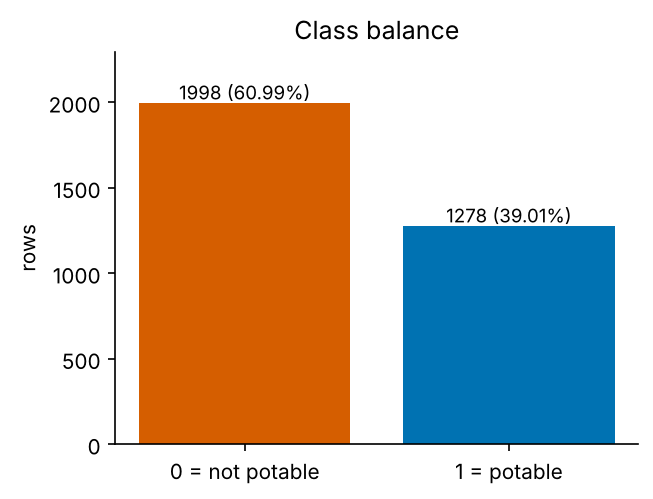

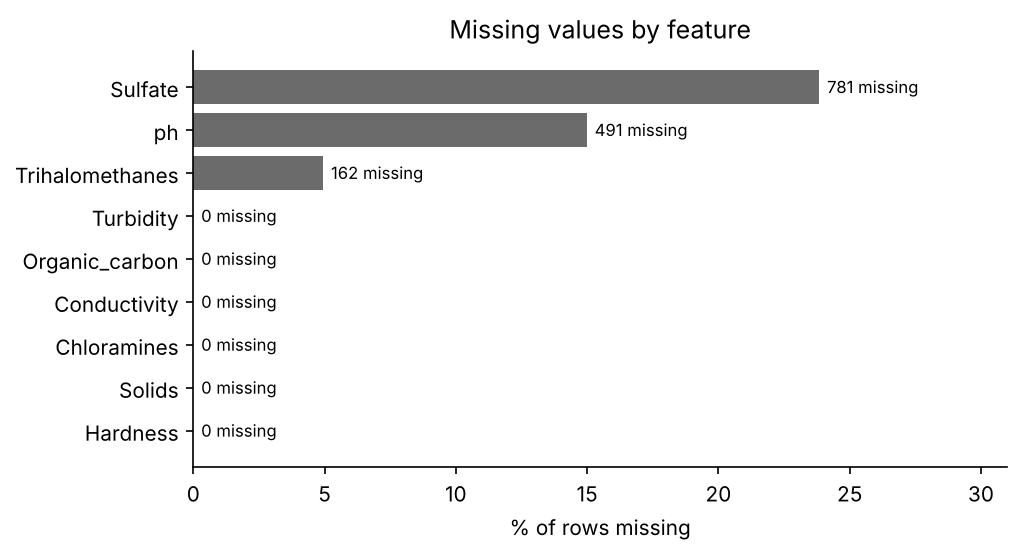

In [4]:
# Missingness plot
miss_pct = 100 * df[FEATURES].isna().mean()
fig, ax = plt.subplots(figsize=(7, 3.6))
order = miss_pct.sort_values().index
ax.barh(order, miss_pct[order], color=C_BASE)
for i, f in enumerate(order):
    ax.text(miss_pct[f] + 0.3, i, f"{int(df[f].isna().sum())} missing", va="center", fontsize=8)
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by feature")
ax.set_xlim(0, max(miss_pct) * 1.3)
save_fig(fig, "missingness.png")

# Class balance plot
fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.bar(["0 = not potable", "1 = potable"], [vc[0], vc[1]], color=[C_NONPOT, C_POT])
for i, v in enumerate([vc[0], vc[1]]):
    ax.text(i, v + 20, f"{v} ({100 * v / len(df):.2f}%)", ha="center", fontsize=9)
ax.set_ylabel("rows"); ax.set_title("Class balance"); ax.set_ylim(0, vc.max() * 1.15)
save_fig(fig, "class_balance.png")

                 mean | not potable (0)  mean | potable (1)
ph                                7.085               7.074
Hardness                        196.733             195.801
Solids                        21777.491           22383.991
Chloramines                       7.092               7.169
Sulfate                         334.564             332.567
Conductivity                    426.730             425.384
Organic_carbon                   14.364              14.161
Trihalomethanes                  66.304              66.540
Turbidity                         3.966               3.968

The class means are very close for every feature, which already hints that the label is hard to predict from these measurements.


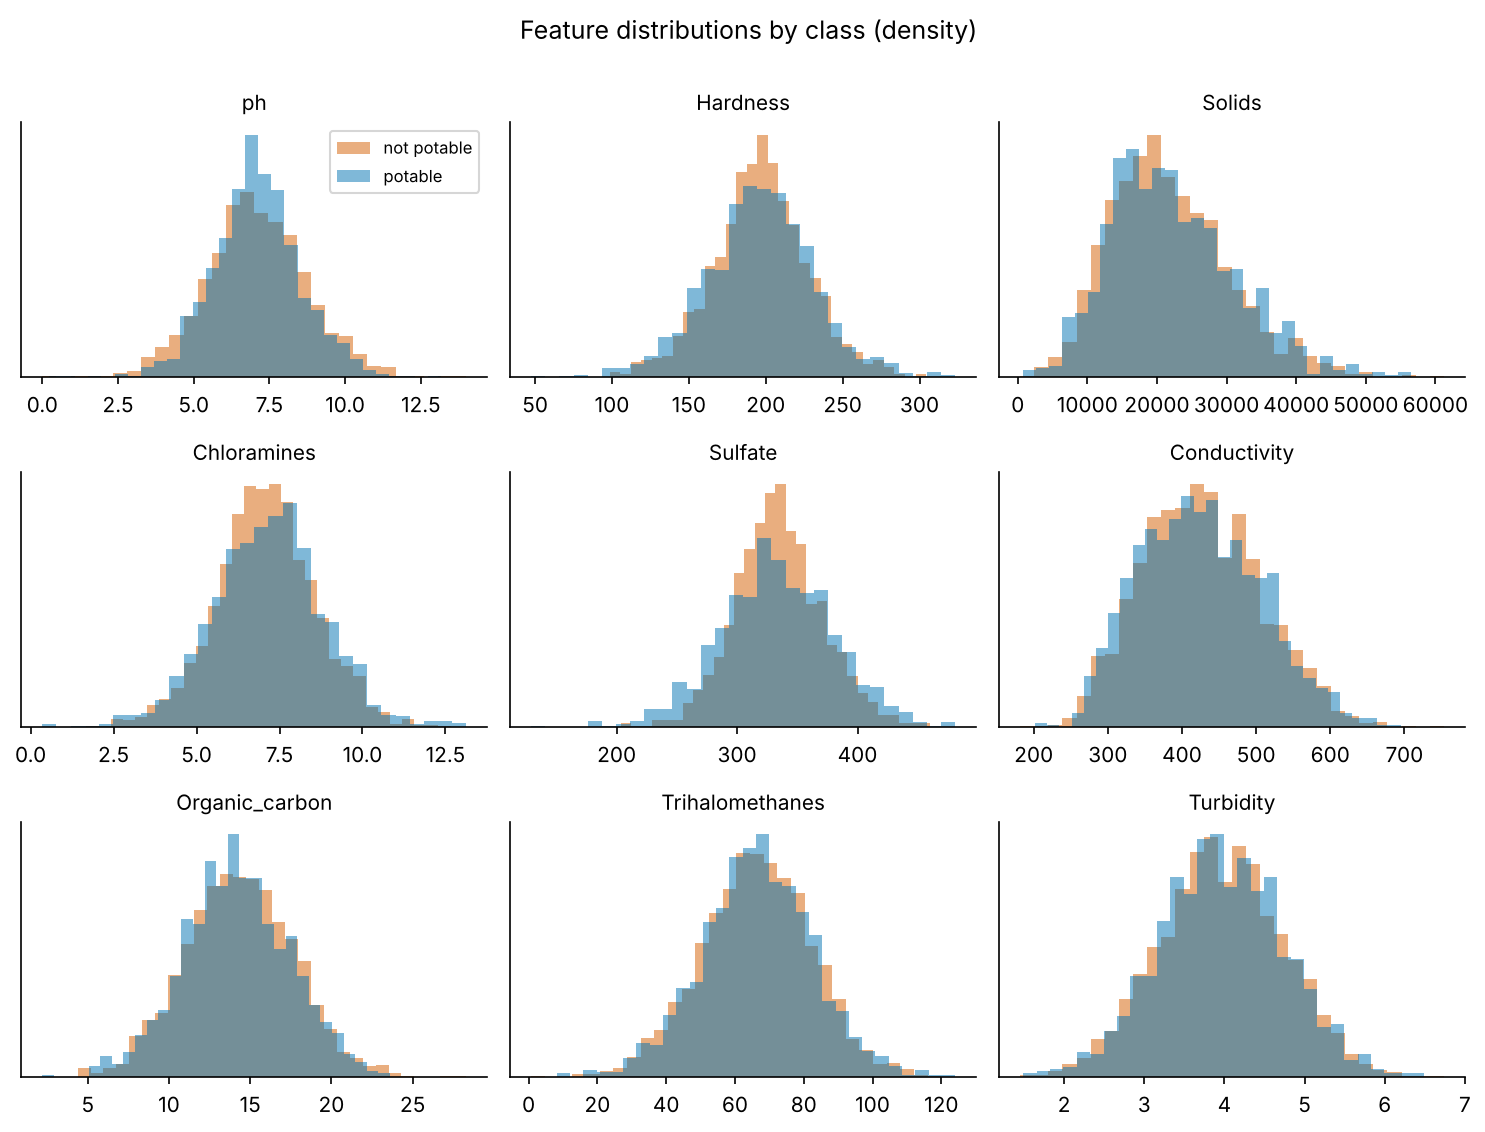

In [5]:
# Feature distributions by class (rows with a missing value are simply left out of that panel)
fig, axes = plt.subplots(3, 3, figsize=(10, 7.5))
for ax, f in zip(axes.ravel(), FEATURES):
    for lab, col, name in [(0, C_NONPOT, "not potable"), (1, C_POT, "potable")]:
        ax.hist(df.loc[df[TARGET] == lab, f].dropna(), bins=30, density=True, alpha=0.5, color=col, label=name)
    ax.set_title(f, fontsize=10); ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle("Feature distributions by class (density)", y=1.0)
fig.tight_layout()
save_fig(fig, "feature_distributions.png")

group_means = df.groupby(TARGET)[FEATURES].mean().T
group_means.columns = ["mean | not potable (0)", "mean | potable (1)"]
print(group_means.round(3).to_string())
print("\nThe class means are very close for every feature, which already hints that the label is hard to predict from these measurements.")

## 3. Split

**Why:** we need an honest estimate of how the final models behave on samples they have never seen. So we lock away a stratified 20% hold-out **test set** now. It is used exactly once, in Section 8, after every choice (hyperparameters, model family, threshold) is frozen. Model comparison and tuning use **stratified 5-fold cross-validation on the 80% training part only**, with identical folds for every scenario and model. Stratification keeps the 61/39 class mix in every part.

In [6]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # identical folds everywhere

print("train:", X_train.shape, "class counts:", y_train.value_counts().sort_index().to_dict(),
      "| share non-potable %.4f" % (y_train == 0).mean())
print("test :", X_test.shape, "class counts:", y_test.value_counts().sort_index().to_dict(),
      "| share non-potable %.4f" % (y_test == 0).mean())
print("\nCV fold sizes (validation part):", [len(v) for _, v in skf.split(X_train, y_train)])
# NOTE: X_test / y_test are NOT touched again until Section 8.

train: (2620, 9) class counts: {0: 1598, 1: 1022} | share non-potable 0.6099
test : (656, 9) class counts: {0: 400, 1: 256} | share non-potable 0.6098

CV fold sizes (validation part): [524, 524, 524, 524, 524]


## 4. Preprocessing and leakage prevention

**Why:** if we computed medians or scaling statistics on the whole dataset, information from validation or test rows would leak into training and make results look better than they are. So all preprocessing lives **inside sklearn Pipelines** and is fitted only on the training part of each CV split:

- median imputation (`SimpleImputer`) for every model (the data has missing values in `ph`, `Sulfate`, `Trihalomethanes`);
- `StandardScaler` for logistic regression only (trees and forests do not need scaling);
- each scenario's columns are selected inside the pipeline with a `ColumnTransformer`.

When the final model is fitted on the full training set, the medians come from training rows only; the test set is later transformed with those training medians. An optional "was this value missing" indicator column is also tested (Experiment 4); it is used only where cross-validation shows a gain larger than its standard error.

In [7]:
SCENARIOS = {
    "A": {"label": "Quick on-site check", "features": ["ph", "Conductivity", "Turbidity"]},
    "B": {"label": "Basic test kit",
          "features": ["ph", "Conductivity", "Turbidity", "Solids", "Hardness", "Chloramines"]},
    "C": {"label": "Full panel",
          "features": ["ph", "Conductivity", "Turbidity", "Solids", "Hardness", "Chloramines",
                       "Sulfate", "Organic_carbon", "Trihalomethanes"]},
}
SCENARIOS["A"]["new_features"] = SCENARIOS["A"]["features"][:]
SCENARIOS["B"]["new_features"] = [f for f in SCENARIOS["B"]["features"] if f not in SCENARIOS["A"]["features"]]
SCENARIOS["C"]["new_features"] = [f for f in SCENARIOS["C"]["features"] if f not in SCENARIOS["B"]["features"]]
assert set(SCENARIOS["C"]["features"]) == set(FEATURES)
assert set(SCENARIOS["A"]["features"]) < set(SCENARIOS["B"]["features"]) < set(SCENARIOS["C"]["features"])
assert [len(SCENARIOS[s]["features"]) for s in "ABC"] == [3, 6, 9]

FAMILIES = ["baseline", "logreg", "tree", "forest"]
NAMES = {"baseline": "Baseline (always non-potable)", "logreg": "Logistic regression",
         "tree": "Decision tree", "forest": "Random forest"}


def make_pipeline(family, feats):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if family == "logreg":
        steps.append(("scale", StandardScaler()))
    prep = ColumnTransformer([("cols", Pipeline(steps), list(feats))], remainder="drop")
    clf = {
        "baseline": DummyClassifier(strategy="most_frequent"),
        "logreg": LogisticRegression(max_iter=2000),          # default penalty is L2
        "tree": DecisionTreeClassifier(random_state=SEED),
        "forest": RandomForestClassifier(random_state=SEED, n_jobs=1),
    }[family]
    return Pipeline([("prep", prep), ("clf", clf)])


print(make_pipeline("logreg", SCENARIOS["A"]["features"]))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cols',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['ph', 'Conductivity',
                                                   'Turbidity'])])),
                ('clf', LogisticRegression(max_iter=2000))])


## 5. Models

**Why these four:** we start from "no skill" (the baseline) and add models of increasing flexibility, so we can see whether extra complexity actually buys anything.

**Baseline: majority class.** *Idea:* always predict non-potable. *Assumption:* none. *Why it is here:* it defines "no skill": 100% non-potable recall, balanced accuracy about 0.50, average precision equal to the class-0 share, and it never predicts potable. It is excluded from model selection.

**Logistic regression (L2).** *Idea:* models the log-odds of the class as a linear combination of the (scaled) features and fits the weights by minimising log-loss plus an L2 penalty on the weights (a smaller `C` means a stronger penalty). *Assumptions:* roughly linear effect of each feature on the log-odds, no strong interactions, moderate outliers. *Why it fits:* small tabular data, fast, hard to overfit, and a sensible reference point for anything more complex.

**Decision tree.** *Idea:* repeatedly split the data on a feature threshold that makes the two parts purer (Gini impurity), giving a set of if/then rules. *Assumptions:* axis-aligned, piecewise-constant structure; no smoothness. *Why it fits:* can capture interactions and non-linear effects and is easy to read, but a single tree has high variance, so depth and leaf size are limited by tuning.

**Random forest.** *Idea:* average many trees, each trained on a bootstrap sample with a random subset of features at each split; the averaging reduces variance. *Assumptions:* same as trees, but less sensitive to any single split. *Why it fits:* usually the strongest of the three on tabular data; its cost is less interpretability and more compute.

**Honest comparison.** We do not assume that the most flexible model wins. Section 6 compares them on cross-validation with fold-to-fold variation, and the selection rule deliberately **prefers the simpler family when it is within one standard error of the best**. If a simple model does as well as a complex one, the notebook says so.

### Scoring definitions

Non-potable (label 0) is the **positive class** for average precision, recall (non-potable) and precision (non-potable). The built-in `"average_precision"` scorer scores label 1, so the tuning scorer is defined explicitly below. Recall (potable) and precision (potable) use label 1 as positive and are named explicitly. Predicted labels use the default 0.5 threshold on the class-0 probability.

In [8]:
def ap_nonpotable(est, X, y):
    i = list(est.classes_).index(0)
    return average_precision_score(np.asarray(y) == 0, est.predict_proba(X)[:, i])


def p0_of(est, X):
    # probability of class 0 (non-potable) from a fitted estimator
    return est.predict_proba(X)[:, list(est.classes_).index(0)]


def np_average_precision(is_pos, score):
    # NumPy average precision: sum_n (R_n - R_{n-1}) * P_n over distinct score thresholds
    is_pos = np.asarray(is_pos, dtype=float)
    score = np.asarray(score, dtype=float)
    if is_pos.sum() == 0:
        return np.nan
    order = np.argsort(-score, kind="mergesort")
    s, pos = score[order], is_pos[order]
    tps, fps = np.cumsum(pos), np.cumsum(1 - pos)
    last = np.r_[np.where(np.diff(s) != 0)[0], len(s) - 1]
    tps, fps = tps[last], fps[last]
    precision, recall = tps / (tps + fps), tps / tps[-1]
    return float(np.sum(np.diff(np.r_[0.0, recall]) * precision))


METRIC_KEYS = ["recall_np", "precision_np", "recall_p", "precision_p", "false_potable_share",
               "balanced_accuracy", "ap_np", "accuracy"]
METRIC_LABELS = {
    "recall_np": "Recall (non-potable)", "precision_np": "Precision (non-potable)",
    "recall_p": "Recall (potable)", "precision_p": "Precision (potable)",
    "false_potable_share": "Share of 'potable' calls that are actually non-potable (1 - precision potable)",
    "balanced_accuracy": "Balanced accuracy", "ap_np": "Average precision (non-potable = positive)",
    "accuracy": "Accuracy (secondary)"}


def metric_values(y_true, p0, thr=0.5):
    # All metrics from true labels and class-0 probabilities. NaN where a metric is undefined.
    y_true = np.asarray(y_true); p0 = np.asarray(p0, dtype=float)
    neg = (y_true == 0)                 # truly non-potable (the positive class for *_np metrics)
    pred0 = p0 >= thr                   # predicted non-potable
    tp = np.sum(neg & pred0); fn = np.sum(neg & ~pred0)
    fp = np.sum(~neg & pred0); tn = np.sum(~neg & ~pred0)
    div = lambda a, b: float(a / b) if b > 0 else np.nan
    rec_np, prec_np = div(tp, tp + fn), div(tp, tp + fp)
    rec_p, prec_p = div(tn, tn + fp), div(tn, tn + fn)     # label 1 positive: TP1 = tn, FP1 = fn
    return {"recall_np": rec_np, "precision_np": prec_np, "recall_p": rec_p, "precision_p": prec_p,
            "false_potable_share": 1 - prec_p, "balanced_accuracy": (rec_np + rec_p) / 2,
            "ap_np": np_average_precision(neg, p0), "accuracy": float((tp + tn) / len(y_true))}


def confusion_counts(y_true, p0, thr=0.5):
    # class 0 (non-potable) is the positive class: tp = non-potable correctly flagged
    y_true = np.asarray(y_true); neg = (y_true == 0); pred0 = np.asarray(p0) >= thr
    return {"tp": int(np.sum(neg & pred0)), "fp": int(np.sum(~neg & pred0)),
            "fn": int(np.sum(neg & ~pred0)), "tn": int(np.sum(~neg & ~pred0))}


def _scorer(key):
    def f(est, X, y):
        return metric_values(y, p0_of(est, X))[key]
    return f


CV_SCORERS = {k: _scorer(k) for k in METRIC_KEYS}
CV_SCORERS["ap_np"] = ap_nonpotable        # the explicit sklearn-based scorer, same as used for tuning

# ---- Self-checks of the metric code (training data only, no test data) ----
rng_chk = np.random.default_rng(SEED)
for _ in range(5):
    yy = rng_chk.integers(0, 2, 300); ss = np.round(rng_chk.random(300), 1)     # rounded scores create ties
    assert abs(np_average_precision(yy == 0, ss) - average_precision_score(yy == 0, ss)) < 1e-12
const = np_average_precision(y_train.to_numpy() == 0, np.ones(len(y_train)))
assert abs(const - (y_train == 0).mean()) < 1e-12
print("NumPy average precision matches sklearn; constant-score AP equals the class-0 share: %.4f" % const)

NumPy average precision matches sklearn; constant-score AP equals the class-0 share: 0.6099


## 6. Cross-validation: tuning experiments (Experiments 1, 2 and 4)

**Why:** model selection must use only the training data. Three clearly separated experiments are run, all with the same identical 5-fold splits, the same scorer and **no test data**:

- **Experiment 1, random-forest hyperparameter tuning (stage 1).** A wider forest grid (depth, leaf size, number of features tried per split) plus the same structural tuning for the tree and logistic regression. Within a family the rule is: best mean CV `ap_nonpotable`, then, among settings within one standard error of that best (SE = std of the best setting's 5 fold scores, ddof=1, divided by sqrt(5)), the setting with the **smallest train-minus-validation gap**. In plain words: if a much less overfit setting is hard to tell apart from the best, take the less overfit one.
- **Experiment 2, class-weight experimentation (stage 2).** With the stage-1 structure fixed, try `None`, `"balanced"` and custom weights that count a non-potable sample 1.5x, 2x or 3x (the forest also tries `"balanced_subsample"`). Choose by mean CV `ap_nonpotable`; among options within one SE, take the one with the best CV balanced accuracy at the 0.5 threshold. Class weights mostly move the *operating point* (how many samples get flagged) rather than how well samples are ranked, so the tables show both.
- **Experiment 4, missing-value indicators (stage 3).** Add a "this value was missing" column (`SimpleImputer(add_indicator=True)`) for features that have missing values. It is adopted only if the paired fold-by-fold gain in CV `ap_nonpotable` is larger than its own standard error; otherwise the plain imputation stays.

**Final model per scenario:** best mean CV `ap_nonpotable`, but a simpler family is preferred if its mean is at least best mean minus SE_best (complexity order: logistic regression < tree < forest). The baseline is excluded from selection. Only these three model families are used.

**Caveats.** (1) The search is greedy and staged (structure, then class weights, then indicators), not a full joint grid, to keep run time reasonable. (2) CV scores of tuned settings are slightly optimistic because the same folds were used to choose them. (3) The held-out test set is used only to score the final models.

In [9]:
from joblib import Parallel, delayed
from sklearn.metrics import average_precision_score

MODEL_FAMS = ["logreg", "tree", "forest"]
N_SPLITS = skf.get_n_splits()
FOLDS = list(skf.split(X_train, y_train))
y_tr_arr = y_train.to_numpy()


def build(sc, fam, params, cw, indicator):
    # one pipeline: scenario columns -> median imputation (+ optional missing indicator) -> (scaling for logreg) -> model
    est = make_pipeline(fam, SCENARIOS[sc]["features"])
    est.set_params(**params)
    est.set_params(clf__class_weight=cw, prep__cols__impute__add_indicator=bool(indicator))
    return est


def _one_fold(est, tr, va):
    m = clone(est).fit(X_train.iloc[tr], y_tr_arr[tr])
    p_tr, p_va = p0_of(m, X_train.iloc[tr]), p0_of(m, X_train.iloc[va])
    mt, mv = metric_values(y_tr_arr[tr], p_tr), metric_values(y_tr_arr[va], p_va)
    mt["ap_np"] = float(average_precision_score(y_tr_arr[tr] == 0, p_tr))     # same quantity as ap_nonpotable
    mv["ap_np"] = float(average_precision_score(y_tr_arr[va] == 0, p_va))
    return mt, mv, p_va


def cv_eval(est):
    # one fit per fold; returns validation and training metrics per fold and out-of-fold class-0 probabilities
    out = Parallel(n_jobs=-1)(delayed(_one_fold)(est, tr, va) for tr, va in FOLDS)
    val = {k: np.array([o[1][k] for o in out], dtype=float) for k in METRIC_KEYS}
    train = {k: np.array([o[0][k] for o in out], dtype=float) for k in METRIC_KEYS}
    oof = np.full(len(y_tr_arr), np.nan)
    for (tr, va), o in zip(FOLDS, out):
        oof[va] = o[2]
    return {"val": val, "train": train, "oof": oof}


def mean_std(a):
    a = np.asarray(a, dtype=float); ok = ~np.isnan(a)
    if ok.sum() == 0:
        return {"mean": None, "std": None, "n_folds_defined": 0}
    return {"mean": float(a[ok].mean()), "std": float(a[ok].std(ddof=1)) if ok.sum() > 1 else None,
            "n_folds_defined": int(ok.sum())}


def summarise(res):
    ap_val, ap_tr = res["val"]["ap_np"], res["train"]["ap_np"]
    return {"cv": {k: mean_std(res["val"][k]) for k in METRIC_KEYS}, "ap_folds": ap_val.tolist(),
            "cv_train_vs_val": {"train_mean": float(ap_tr.mean()), "val_mean": float(ap_val.mean()),
                                "gap": float(ap_tr.mean() - ap_val.mean())}}


# sanity check: the fold-by-fold AP used in cv_eval equals the explicit tuning scorer ap_nonpotable
_chk = build("A", "logreg", {"clf__C": 1}, "balanced", False)
_a = cv_eval(_chk)["val"]["ap_np"].mean()
_b = cross_validate(clone(_chk), X_train, y_train, cv=skf, scoring=ap_nonpotable)["test_score"].mean()
assert abs(_a - _b) < 1e-9, (_a, _b)
print("cv_eval average precision matches the ap_nonpotable scorer.")

cv_eval average precision matches the ap_nonpotable scorer.


In [10]:
# ---- Experiment 1 (stage 1): structural tuning, class weight fixed at "balanced" for this stage ----
STAGE1 = {
    "logreg": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "tree": {"clf__max_depth": [3, 4, 5, 6, 8, 12], "clf__min_samples_leaf": [3, 10, 30, 60]},
    "forest": {"clf__n_estimators": [200], "clf__max_depth": [4, 6, 10, 15], "clf__min_samples_leaf": [3, 10, 20],
               "clf__max_features": ["sqrt", 0.5]},
}
N_SPLITS = skf.get_n_splits()


def regularised_pick(gs):
    # best mean CV AP; then, within one SE of it, the smallest train-validation gap
    r = gs.cv_results_
    folds = np.column_stack([r[f"split{i}_test_score"] for i in range(N_SPLITS)])
    means = folds.mean(axis=1)
    gaps = r["mean_train_score"] - means
    b = int(np.argmax(means))
    se = float(folds[b].std(ddof=1) / np.sqrt(N_SPLITS))
    cands = np.where(means >= means[b] - se)[0]
    c = int(min(cands, key=lambda i: (round(float(gaps[i]), 6), -means[i])))
    rows = [{**{k.replace("clf__", ""): v for k, v in r["params"][i].items()}, "cv_ap": float(means[i]), "gap": float(gaps[i])}
            for i in range(len(means))]
    return {"best_params": r["params"][b], "chosen_params": r["params"][c], "se_best": se,
            "n_candidates": int(len(cands)), "n_settings": int(len(means)),
            "best_mean": float(means[b]), "chosen_mean": float(means[c]),
            "best_gap": float(gaps[b]), "chosen_gap": float(gaps[c]), "rows": rows}


STAGE1_PICK = {}
for sc in SCENARIOS:
    for fam in MODEL_FAMS:
        base = make_pipeline(fam, SCENARIOS[sc]["features"]).set_params(clf__class_weight="balanced")
        gs = GridSearchCV(base, STAGE1[fam], scoring=ap_nonpotable, cv=skf, n_jobs=-1, refit=False,
                          return_train_score=True).fit(X_train, y_train)
        info = regularised_pick(gs)
        STAGE1_PICK[(sc, fam)] = info
        short = lambda d: {k.replace("clf__", ""): v for k, v in d.items()}
        print(f"{sc}/{fam:6s} best-by-mean CV AP {info['best_mean']:.4f} (gap {info['best_gap']:+.3f}) | chosen: CV AP {info['chosen_mean']:.4f}, "
              f"gap {info['chosen_gap']:+.3f}  ({info['n_candidates']}/{info['n_settings']} settings within 1 SE) -> {short(info['chosen_params'])}")
        for p, vals in STAGE1[fam].items():
            numeric = [x for x in vals if isinstance(x, (int, float)) and not isinstance(x, bool)]
            if len(numeric) > 2 and info["chosen_params"][p] in (min(numeric), max(numeric)):
                print(f"      [note] {p.replace('clf__', '')} = {info['chosen_params'][p]} is at the edge of its grid (grid not extended)")

A/logreg best-by-mean CV AP 0.5955 (gap +0.028) | chosen: CV AP 0.5955, gap +0.028  (5/5 settings within 1 SE) -> {'C': 100}
      [note] C = 100 is at the edge of its grid (grid not extended)
A/tree   best-by-mean CV AP 0.6296 (gap +0.058) | chosen: CV AP 0.6250, gap +0.018  (18/24 settings within 1 SE) -> {'max_depth': 3, 'min_samples_leaf': 60}
      [note] max_depth = 3 is at the edge of its grid (grid not extended)
      [note] min_samples_leaf = 60 is at the edge of its grid (grid not extended)
A/forest best-by-mean CV AP 0.6454 (gap +0.139) | chosen: CV AP 0.6429, gap +0.107  (22/24 settings within 1 SE) -> {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 200}
      [note] max_depth = 4 is at the edge of its grid (grid not extended)
      [note] min_samples_leaf = 20 is at the edge of its grid (grid not extended)
B/logreg best-by-mean CV AP 0.5941 (gap +0.026) | chosen: CV AP 0.5941, gap +0.026  (5/5 settings within 1 SE) -> {'C': 10}
B/tree   bes

In [11]:
# ---- Experiment 2 (stage 2): class-weight experiment, stage-1 structure fixed ----
CW_OPTIONS = [("none", None), ("balanced", "balanced"), ("nonpot_x1.5", {0: 1.5, 1: 1.0}),
              ("nonpot_x2", {0: 2.0, 1: 1.0}), ("nonpot_x3", {0: 3.0, 1: 1.0})]
CW_EXTRA = {"forest": [("balanced_subsample", "balanced_subsample")]}
CW_LOOKUP = dict(CW_OPTIONS + CW_EXTRA["forest"])
CW_RES, CW_CHOSEN, CW_INFO = {}, {}, {}
for sc in SCENARIOS:
    for fam in MODEL_FAMS:
        p1 = STAGE1_PICK[(sc, fam)]["chosen_params"]
        res = {name: cv_eval(build(sc, fam, p1, cw, False)) for name, cw in CW_OPTIONS + CW_EXTRA.get(fam, [])}
        means = {n: float(r["val"]["ap_np"].mean()) for n, r in res.items()}
        best = max(means, key=means.get)
        se = float(res[best]["val"]["ap_np"].std(ddof=1) / np.sqrt(N_SPLITS))
        eligible = [n for n in res if means[n] >= means[best] - se]
        chosen = max(eligible, key=lambda n: float(res[n]["val"]["balanced_accuracy"].mean()))
        CW_RES[(sc, fam)], CW_CHOSEN[(sc, fam)] = res, chosen
        CW_INFO[(sc, fam)] = {"best_by_ap": best, "se_best": se, "eligible": eligible, "chosen": chosen}
        print(f"{sc}/{fam:6s} CV AP by weight: " + ", ".join(f"{n} {means[n]:.3f}" for n in res) + f"  -> chosen: {chosen}")
        print("             CV non-potable recall: " + ", ".join(f"{n} {res[n]['val']['recall_np'].mean():.2f}" for n in res))

A/logreg CV AP by weight: none 0.595, balanced 0.596, nonpot_x1.5 0.595, nonpot_x2 0.595, nonpot_x3 0.594  -> chosen: none
             CV non-potable recall: none 1.00, balanced 0.48, nonpot_x1.5 1.00, nonpot_x2 1.00, nonpot_x3 1.00
A/tree   CV AP by weight: none 0.626, balanced 0.625, nonpot_x1.5 0.626, nonpot_x2 0.626, nonpot_x3 0.626  -> chosen: balanced
             CV non-potable recall: none 0.95, balanced 0.21, nonpot_x1.5 1.00, nonpot_x2 1.00, nonpot_x3 1.00
A/forest CV AP by weight: none 0.641, balanced 0.643, nonpot_x1.5 0.642, nonpot_x2 0.638, nonpot_x3 0.638, balanced_subsample 0.640  -> chosen: balanced
             CV non-potable recall: none 1.00, balanced 0.46, nonpot_x1.5 1.00, nonpot_x2 1.00, nonpot_x3 1.00, balanced_subsample 0.47
B/logreg CV AP by weight: none 0.593, balanced 0.594, nonpot_x1.5 0.592, nonpot_x2 0.592, nonpot_x3 0.592  -> chosen: none
             CV non-potable recall: none 1.00, balanced 0.52, nonpot_x1.5 1.00, nonpot_x2 1.00, nonpot_x3 1.00
B/tre

In [12]:
# ---- Experiment 4 (stage 3): missing-value indicators, everything else fixed ----
IND_INFO, FINAL_CFG, CVF, BEST_EST = {}, {}, {}, {}
for sc in SCENARIOS:
    feats = SCENARIOS[sc]["features"]
    for fam in MODEL_FAMS:
        p1, cwn = STAGE1_PICK[(sc, fam)]["chosen_params"], CW_CHOSEN[(sc, fam)]
        r0 = CW_RES[(sc, fam)][cwn]                               # same configuration, indicator off (already computed)
        r1 = cv_eval(build(sc, fam, p1, CW_LOOKUP[cwn], True))
        d = r1["val"]["ap_np"] - r0["val"]["ap_np"]
        se = float(d.std(ddof=1) / np.sqrt(N_SPLITS))
        adopt = bool(d.mean() > se)
        IND_INFO[(sc, fam)] = {"cv_ap_without": float(r0["val"]["ap_np"].mean()), "cv_ap_with": float(r1["val"]["ap_np"].mean()),
                               "paired_diff_mean": float(d.mean()), "paired_diff_se": se, "adopted": adopt}
        FINAL_CFG[(sc, fam)] = {"params": p1, "cw_name": cwn, "indicator": adopt}
        CVF[(sc, fam)] = r1 if adopt else r0
        BEST_EST[(sc, fam)] = build(sc, fam, p1, CW_LOOKUP[cwn], adopt).fit(X_train, y_train)
        print(f"{sc}/{fam:6s} CV AP without indicators {r0['val']['ap_np'].mean():.4f}, with {r1['val']['ap_np'].mean():.4f} "
              f"(paired gain {d.mean():+.4f}, SE {se:.4f}) -> {'ADOPTED' if adopt else 'not adopted'}")
    BEST_EST[(sc, "baseline")] = make_pipeline("baseline", feats).fit(X_train, y_train)
    CVF[(sc, "baseline")] = cv_eval(make_pipeline("baseline", feats))

A/logreg CV AP without indicators 0.5952, with 0.6081 (paired gain +0.0129, SE 0.0081) -> ADOPTED
A/tree   CV AP without indicators 0.6250, with 0.6233 (paired gain -0.0017, SE 0.0017) -> not adopted
A/forest CV AP without indicators 0.6429, with 0.6464 (paired gain +0.0035, SE 0.0027) -> ADOPTED
B/logreg CV AP without indicators 0.5928, with 0.5989 (paired gain +0.0062, SE 0.0063) -> not adopted
B/tree   CV AP without indicators 0.6741, with 0.6752 (paired gain +0.0012, SE 0.0012) -> not adopted
B/forest CV AP without indicators 0.7204, with 0.7205 (paired gain +0.0001, SE 0.0014) -> not adopted
C/logreg CV AP without indicators 0.5852, with 0.6005 (paired gain +0.0153, SE 0.0065) -> ADOPTED
C/tree   CV AP without indicators 0.7019, with 0.7019 (paired gain +0.0000, SE 0.0000) -> not adopted
C/forest CV AP without indicators 0.7618, with 0.7616 (paired gain -0.0002, SE 0.0044) -> not adopted


In [13]:
# ---- Cross-validated metrics of the final settings (identical folds) ----
CV = {k: summarise(v) for k, v in CVF.items()}
rows = []
for sc in SCENARIOS:
    for fam in MODEL_FAMS:
        b = CV[(sc, fam)]
        rows.append({"scen": sc, "model": fam, "CV AP": b["cv"]["ap_np"]["mean"], "train-val gap": b["cv_train_vs_val"]["gap"],
                     "recall(0)": b["cv"]["recall_np"]["mean"], "false-pot": b["cv"]["false_potable_share"]["mean"],
                     "bal.acc": b["cv"]["balanced_accuracy"]["mean"],
                     "weights": FINAL_CFG[(sc, fam)]["cw_name"], "indicator": FINAL_CFG[(sc, fam)]["indicator"]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nbaseline CV AP:", {sc: round(CV[(sc, 'baseline')]['cv']['ap_np']['mean'], 3) for sc in SCENARIOS})

# ---- Selection rule (documented, fixed before looking at test data) ----
ORDER = MODEL_FAMS
SELECTION, FINAL = {}, {}
for sc in SCENARIOS:
    means = {f: CV[(sc, f)]["cv"]["ap_np"]["mean"] for f in ORDER}
    best = max(ORDER, key=lambda f: means[f])
    folds = np.asarray(CV[(sc, best)]["ap_folds"])
    se = float(folds.std(ddof=1) / np.sqrt(len(folds)))
    cutoff = means[best] - se
    chosen = next(f for f in ORDER if means[f] >= cutoff)
    FINAL[sc] = chosen
    base_ap = CV[(sc, "baseline")]["cv"]["ap_np"]["mean"]
    SELECTION[sc] = {"rule": "highest mean CV AP; simpler family preferred if mean >= best mean - SE_best",
                     "cv_ap_means": means, "best_by_mean": best, "best_mean": means[best],
                     "se_best": se, "cutoff": cutoff, "chosen": chosen, "baseline_cv_ap": base_ap}
    print(f"Scenario {sc}: CV AP means {({k: round(v, 4) for k, v in means.items()})}; best = {best} (SE_best {se:.4f}, cutoff {cutoff:.4f}) -> FINAL = {chosen}")
    print(f"   final CV AP {means[chosen]:.3f} vs baseline {base_ap:.3f} ({means[chosen] - base_ap:+.3f}); "
          f"train-vs-validation gap {CV[(sc, chosen)]['cv_train_vs_val']['gap']:+.3f}")

scen  model  CV AP  train-val gap  recall(0)  false-pot  bal.acc            weights  indicator
   A logreg  0.608          0.020      1.000        NaN    0.500               none       True
   A   tree  0.625          0.018      0.214      0.594    0.525           balanced      False
   A forest  0.646          0.101      0.446      0.603    0.508           balanced       True
   B logreg  0.593          0.026      1.000        NaN    0.500               none      False
   B   tree  0.674          0.070      0.510      0.564    0.551           balanced      False
   B forest  0.720          0.128      0.621      0.520    0.584 balanced_subsample      False
   C logreg  0.600          0.033      1.000        NaN    0.500               none       True
   C   tree  0.702          0.053      0.913      0.406    0.556        nonpot_x1.5      False
   C forest  0.762          0.199      0.736      0.443    0.628           balanced      False

baseline CV AP: {'A': 0.61, 'B': 0.61, 'C': 0.61}

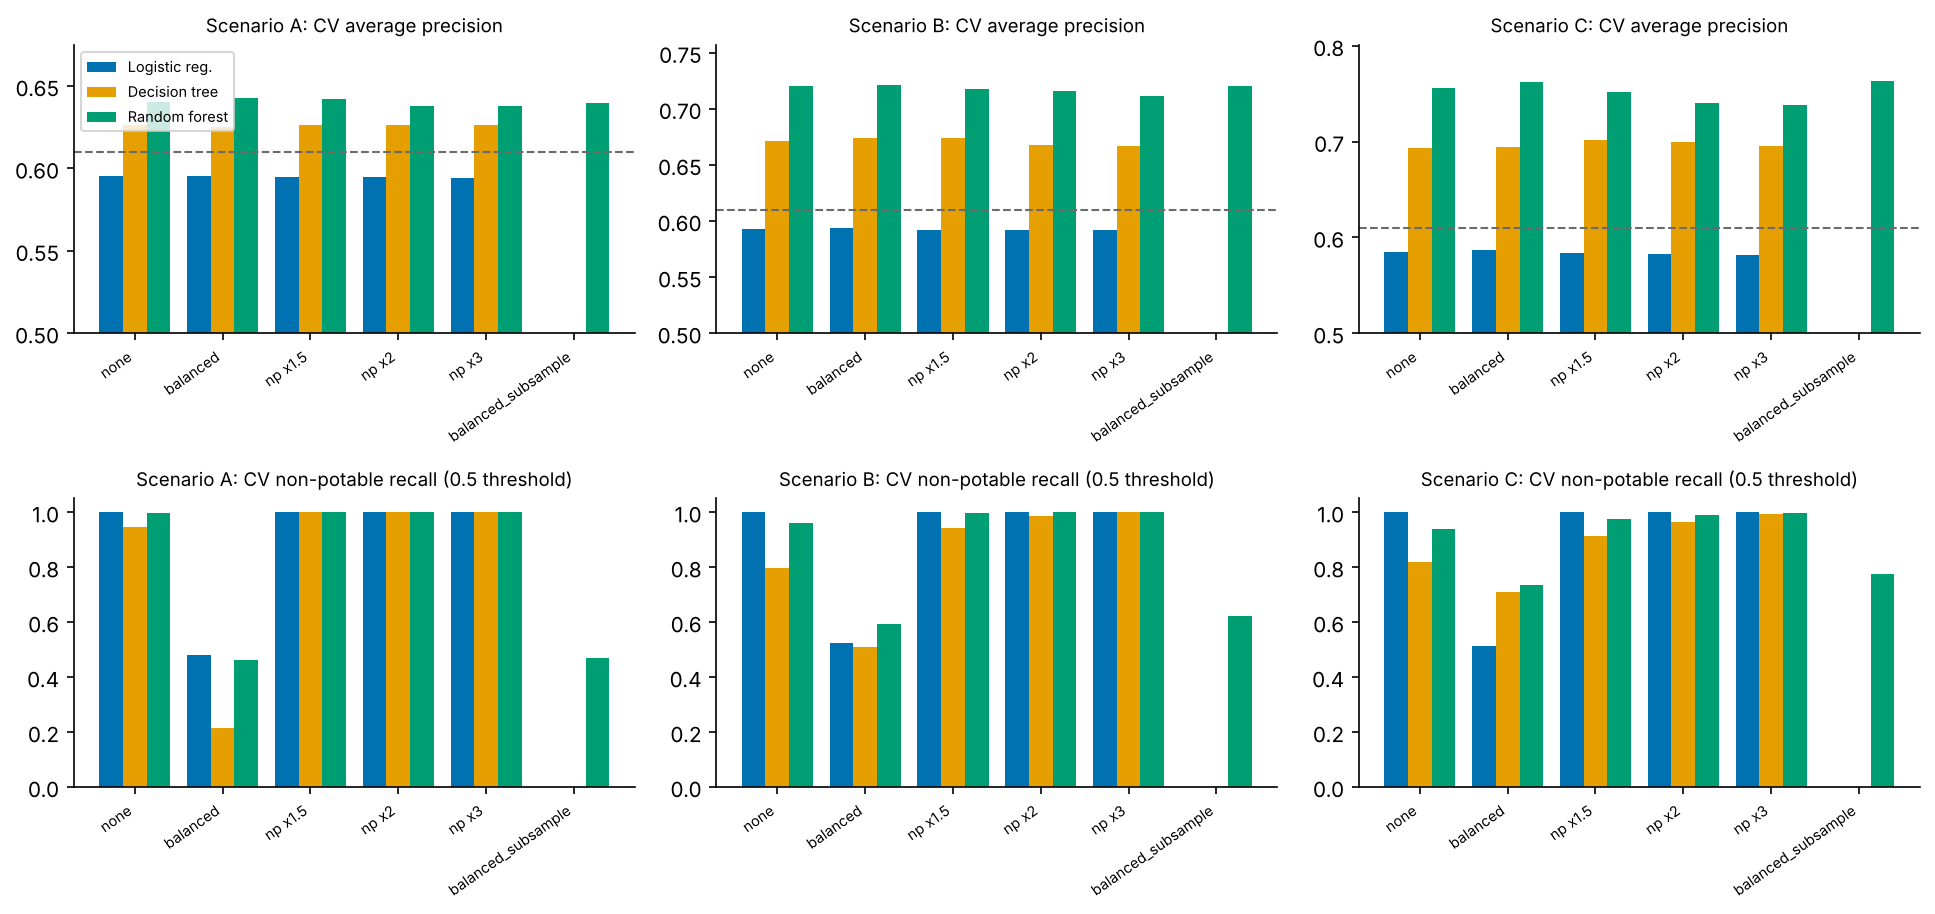

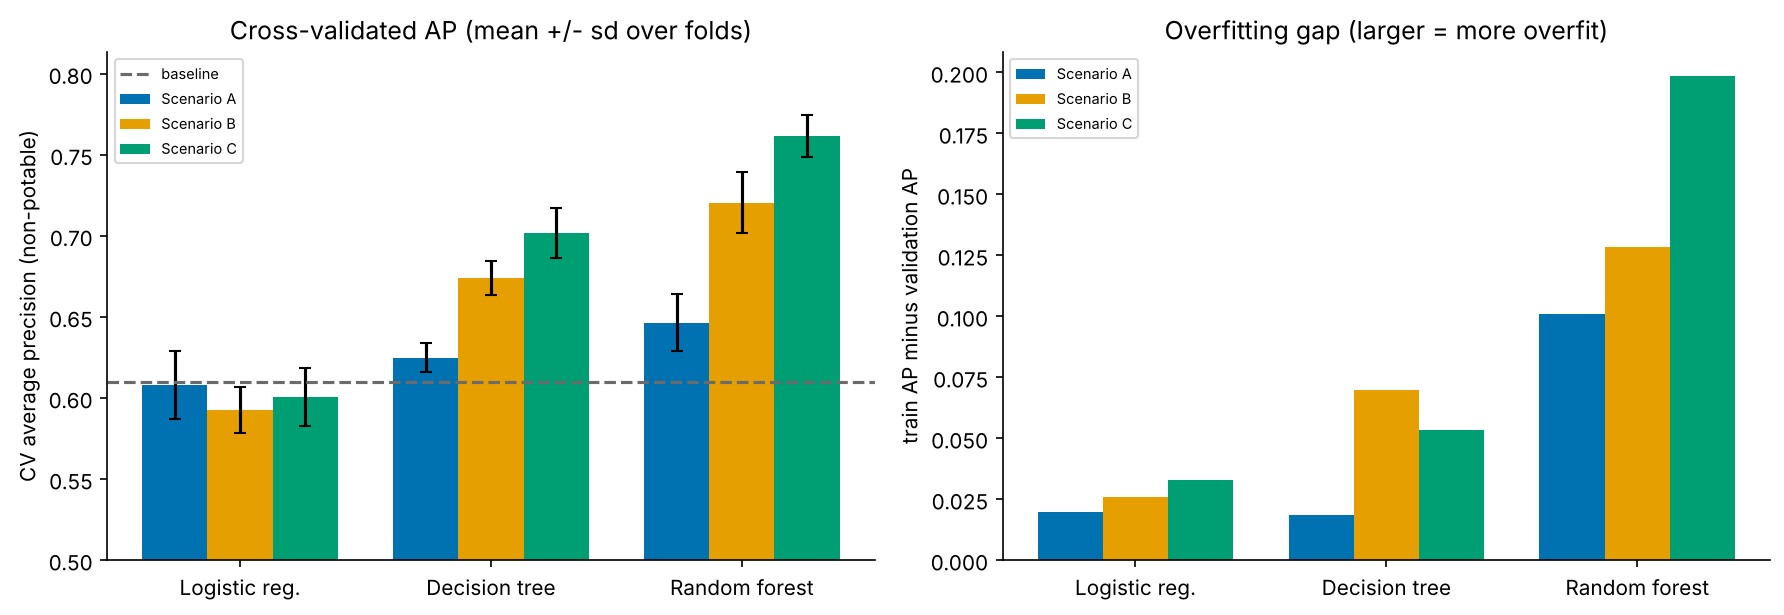

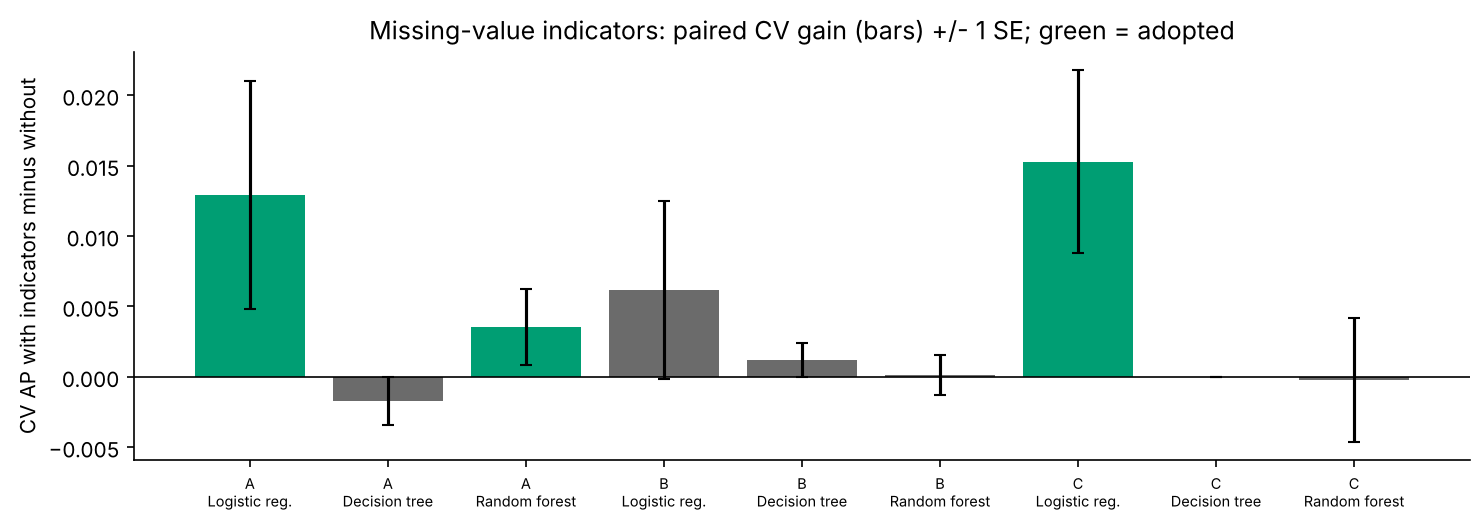

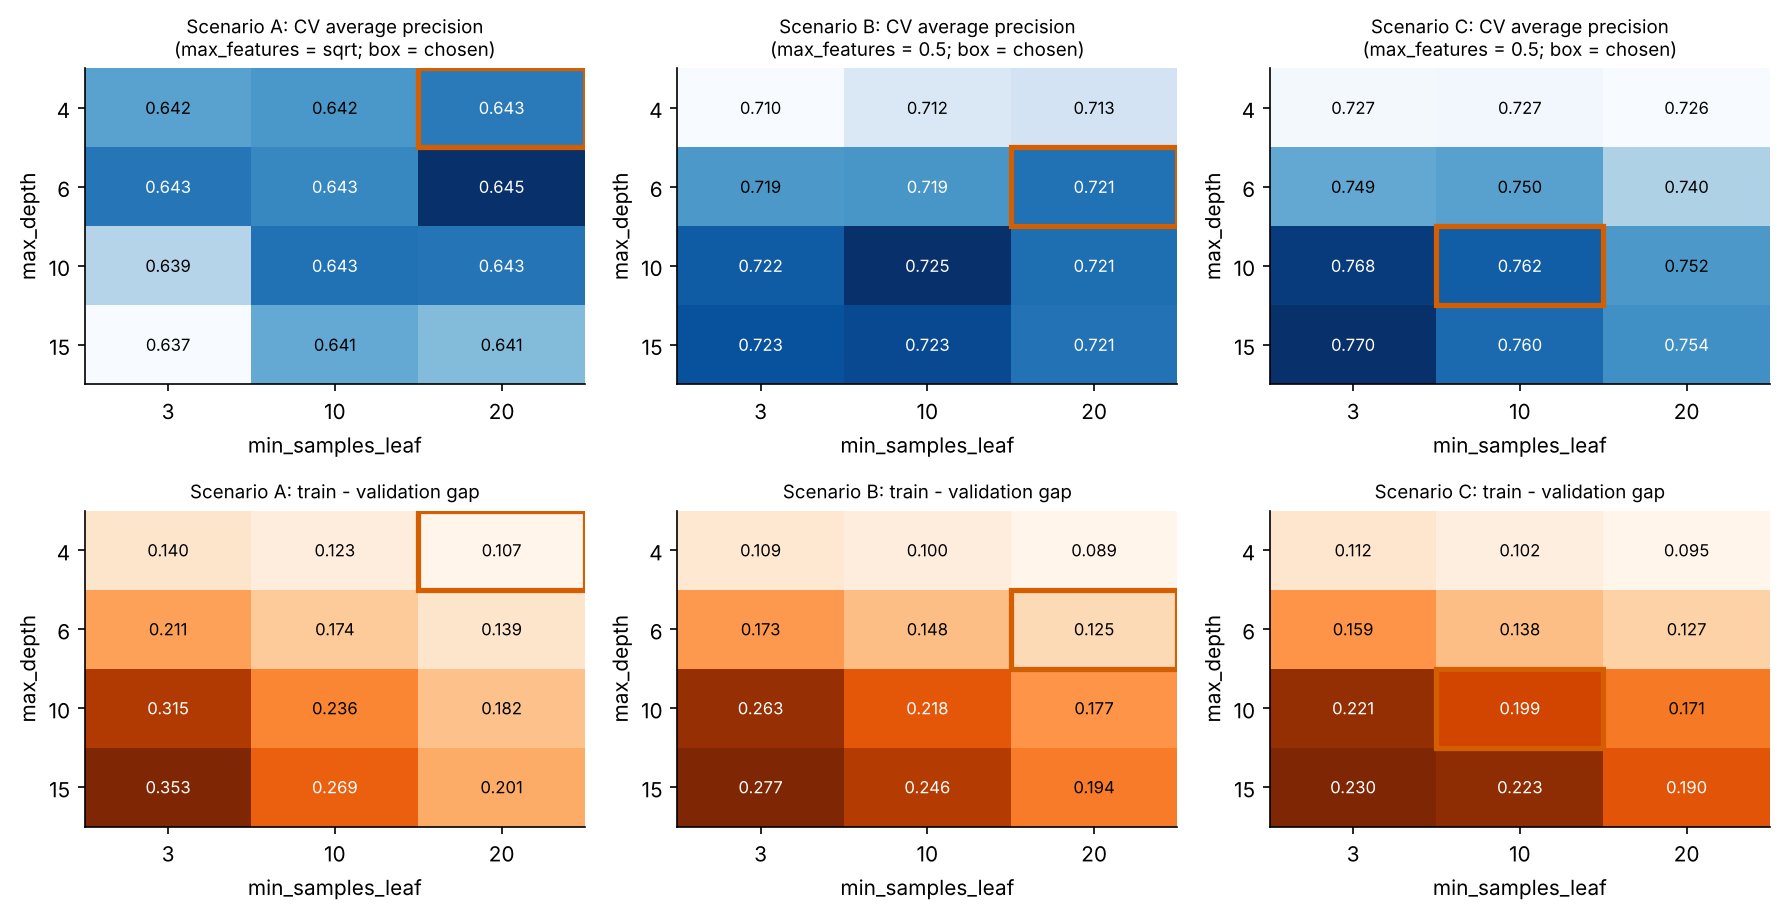

In [14]:
# ---- Plots for Experiments 1, 2 and 4, plus the CV summary ----
SHORT = {"logreg": "Logistic reg.", "tree": "Decision tree", "forest": "Random forest"}
C_FAM = {"logreg": "#0072B2", "tree": "#E69F00", "forest": "#009E73"}

# Experiment 1: forest grid heatmaps (chosen max_features), AP and gap
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for j, sc in enumerate(SCENARIOS):
    info = STAGE1_PICK[(sc, "forest")]
    mf = info["chosen_params"]["clf__max_features"]
    rws = [r for r in info["rows"] if r["max_features"] == mf]
    depths = sorted({r["max_depth"] for r in rws}); leaves = sorted({r["min_samples_leaf"] for r in rws})
    for i, (key, ttl, cmap) in enumerate([("cv_ap", "CV average precision", "Blues"), ("gap", "train - validation gap", "Oranges")]):
        M = np.array([[next(r[key] for r in rws if r["max_depth"] == d and r["min_samples_leaf"] == l) for l in leaves] for d in depths])
        ax = axes[i, j]; ax.imshow(M, cmap=cmap, aspect="auto")
        for (a, b), v in np.ndenumerate(M):
            ax.text(b, a, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if v > (M.min() + 0.6 * (M.max() - M.min())) else "black")
        ax.set_xticks(range(len(leaves))); ax.set_xticklabels(leaves); ax.set_yticks(range(len(depths))); ax.set_yticklabels(depths)
        ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
        cd, cl = info["chosen_params"]["clf__max_depth"], info["chosen_params"]["clf__min_samples_leaf"]
        ax.add_patch(plt.Rectangle((leaves.index(cl) - 0.5, depths.index(cd) - 0.5), 1, 1, fill=False, ec="#D55E00", lw=2.5))
        ax.set_title(f"Scenario {sc}: {ttl}" + (f"\n(max_features = {mf}; box = chosen)" if i == 0 else ""), fontsize=9)
fig.tight_layout(); save_fig(fig, "rf_tuning.png")

# Experiment 2: class weights (CV AP stays flat; non-potable recall moves)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2))
names_all = [n for n, _ in CW_OPTIONS] + ["balanced_subsample"]
for j, sc in enumerate(SCENARIOS):
    for i, (key, ttl) in enumerate([("ap_np", "CV average precision"), ("recall_np", "CV non-potable recall (0.5 threshold)")]):
        ax = axes[i, j]; w = 0.27
        for k, fam in enumerate(MODEL_FAMS):
            vals = [CW_RES[(sc, fam)][n]["val"][key].mean() if n in CW_RES[(sc, fam)] else np.nan for n in names_all]
            ax.bar(np.arange(len(names_all)) + (k - 1) * w, vals, w, color=C_FAM[fam], label=SHORT[fam])
        ax.set_xticks(range(len(names_all))); ax.set_xticklabels([n.replace("nonpot_", "np ") for n in names_all], rotation=35, ha="right", fontsize=7)
        if key == "ap_np":
            ax.axhline(CV[(sc, "baseline")]["cv"]["ap_np"]["mean"], color=C_BASE, ls="--", lw=1); ax.set_ylim(0.5, None)
        ax.set_title(f"Scenario {sc}: {ttl}", fontsize=9)
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); save_fig(fig, "class_weight.png")

# Experiment 4: paired CV gain from missing-value indicators
fig, ax = plt.subplots(figsize=(10, 3.6))
labs, dm, dse, cols = [], [], [], []
for sc in SCENARIOS:
    for fam in MODEL_FAMS:
        i = IND_INFO[(sc, fam)]; labs.append(f"{sc}\n{SHORT[fam]}"); dm.append(i["paired_diff_mean"]); dse.append(i["paired_diff_se"])
        cols.append("#009E73" if i["adopted"] else C_BASE)
ax.bar(range(len(labs)), dm, yerr=dse, capsize=3, color=cols); ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=7)
ax.set_ylabel("CV AP with indicators minus without"); ax.set_title("Missing-value indicators: paired CV gain (bars) +/- 1 SE; green = adopted")
fig.tight_layout(); save_fig(fig, "missing_indicators.png")

# CV summary: final CV AP (bars) and overfitting gap
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2)); w = 0.26
for j, sc in enumerate(SCENARIOS):
    xs = np.arange(3) + (j - 1) * w
    axes[0].bar(xs, [CV[(sc, f)]["cv"]["ap_np"]["mean"] for f in MODEL_FAMS], w, yerr=[CV[(sc, f)]["cv"]["ap_np"]["std"] for f in MODEL_FAMS],
                capsize=3, color=C_SCEN[sc], label=f"Scenario {sc}")
axes[0].axhline(CV[("A", "baseline")]["cv"]["ap_np"]["mean"], color=C_BASE, ls="--", label="baseline")
axes[0].set_xticks(range(3)); axes[0].set_xticklabels([SHORT[f] for f in MODEL_FAMS]); axes[0].set_ylim(0.5, None)
axes[0].set_ylabel("CV average precision (non-potable)"); axes[0].set_title("Cross-validated AP (mean +/- sd over folds)"); axes[0].legend(fontsize=7)
for j, sc in enumerate(SCENARIOS):
    xs = np.arange(3) + (j - 1) * w
    axes[1].bar(xs, [CV[(sc, f)]["cv_train_vs_val"]["gap"] for f in MODEL_FAMS], w, color=C_SCEN[sc], label=f"Scenario {sc}")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels([SHORT[f] for f in MODEL_FAMS])
axes[1].set_ylabel("train AP minus validation AP"); axes[1].set_title("Overfitting gap (larger = more overfit)"); axes[1].legend(fontsize=7)
fig.tight_layout(); save_fig(fig, "cv_results.png")

## 7. Experiment 3: classification-threshold tuning (no test data)

**Why:** a model outputs a probability; the threshold decides which samples get called non-potable. Moving it trades missed non-potable samples against false alarms, and it is the main lever on the share of wrong "potable" calls. To avoid choosing a threshold by looking at the test set, all thresholds are chosen **here, on training data only**, from the **out-of-fold** class-0 probabilities of each scenario's final model (each training row is scored by a model that never saw it, from the same 5 folds):

1. **default**: 0.5, the headline setting.
2. **balanced**: the threshold that maximises out-of-fold balanced accuracy (searched on a 0.01 grid from 0.05 to 0.95). It treats missing a non-potable and wrongly flagging a potable sample symmetrically.
3. **recall90**: `t = np.quantile(p0[y == 0], 0.10)`, so that 90% of truly non-potable training rows are flagged. It leans towards catching non-potable samples (the costlier error).

Each is **frozen** and applied once to the saved test probabilities in Section 9 (predict non-potable if `p0 >= t`). There is no control that picks a threshold from test results. The sweep below is computed on training data and is only for choosing and for understanding the trade-off.

Scenario A (forest), rule default : FROZEN t = 0.500 | training out-of-fold: non-potable recall 0.446, potable cleared 0.569, wrong-'potable' share 0.603, balanced accuracy 0.508
Scenario A (forest), rule balanced: FROZEN t = 0.540 | training out-of-fold: non-potable recall 0.155, potable cleared 0.898, wrong-'potable' share 0.595, balanced accuracy 0.526
Scenario A (forest), rule recall90: FROZEN t = 0.461 | training out-of-fold: non-potable recall 0.900, potable cleared 0.116, wrong-'potable' share 0.573, balanced accuracy 0.508
Scenario B (forest), rule default : FROZEN t = 0.500 | training out-of-fold: non-potable recall 0.621, potable cleared 0.546, wrong-'potable' share 0.520, balanced accuracy 0.584
Scenario B (forest), rule balanced: FROZEN t = 0.500 | training out-of-fold: non-potable recall 0.621, potable cleared 0.546, wrong-'potable' share 0.520, balanced accuracy 0.584
Scenario B (forest), rule recall90: FROZEN t = 0.444 | training out-of-fold: non-potable recall 0.900, po

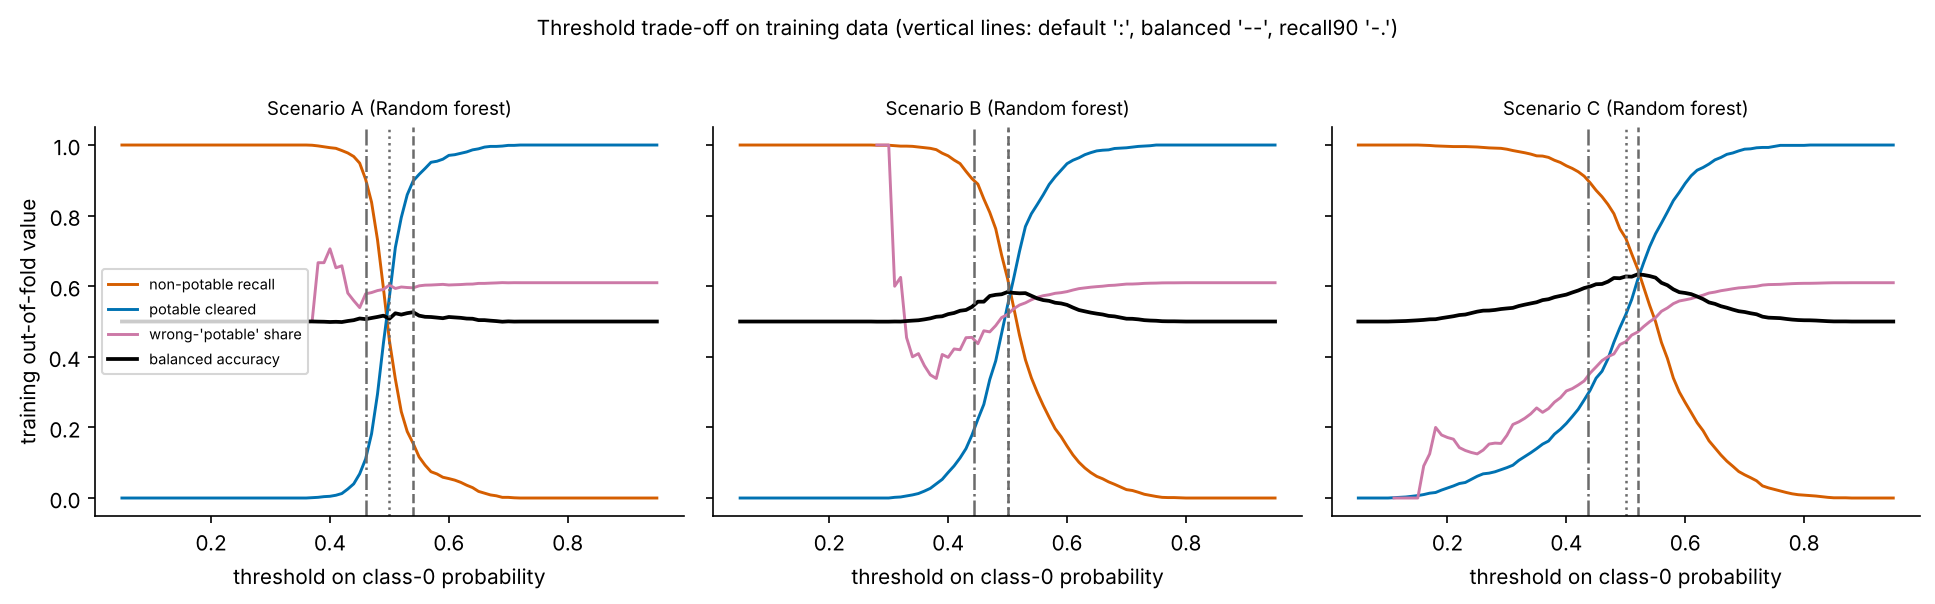

In [15]:
RULES = ["default", "balanced", "recall90"]
RULE_TEXT = {"default": "default threshold 0.5",
             "balanced": "threshold maximising out-of-fold balanced accuracy on the training data",
             "recall90": "10th percentile of out-of-fold class-0 probabilities of truly non-potable training rows (target 90% non-potable recall)"}
GRID_T = np.round(np.arange(0.05, 0.9501, 0.01), 2)
THRESH = {r: {} for r in RULES}
THRESH_INFO = {r: {} for r in RULES}
OOF_SWEEP = {}
for sc in SCENARIOS:
    p0_oof = CVF[(sc, FINAL[sc])]["oof"]
    assert not np.isnan(p0_oof).any()
    sweep = [metric_values(y_tr_arr, p0_oof, float(t)) for t in GRID_T]
    bal = np.array([s["balanced_accuracy"] for s in sweep])
    THRESH["default"][sc] = 0.5
    THRESH["balanced"][sc] = float(GRID_T[int(np.argmax(bal))])
    THRESH["recall90"][sc] = float(np.quantile(p0_oof[y_tr_arr == 0], 0.10))
    OOF_SWEEP[sc] = {"threshold": GRID_T.tolist(), **{k: [s[k] for s in sweep] for k in ["recall_np", "recall_p", "false_potable_share", "balanced_accuracy", "precision_np"]}}
    for r in RULES:
        o = metric_values(y_tr_arr, p0_oof, THRESH[r][sc])
        THRESH_INFO[r][sc] = {"oof_recall_np": o["recall_np"], "oof_recall_p": o["recall_p"], "oof_precision_np": o["precision_np"],
                              "oof_false_potable_share": o["false_potable_share"], "oof_balanced_accuracy": o["balanced_accuracy"]}
        print(f"Scenario {sc} ({FINAL[sc]}), rule {r:8s}: FROZEN t = {THRESH[r][sc]:.3f} | training out-of-fold: non-potable recall {o['recall_np']:.3f}, "
              f"potable cleared {o['recall_p']:.3f}, wrong-'potable' share {o['false_potable_share']:.3f}, balanced accuracy {o['balanced_accuracy']:.3f}")

# Plot: out-of-fold trade-off with the frozen thresholds
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, sc in zip(axes, SCENARIOS):
    sw = OOF_SWEEP[sc]
    for key, col, lab in [("recall_np", C_NONPOT, "non-potable recall"), ("recall_p", C_POT, "potable cleared"),
                          ("false_potable_share", "#CC79A7", "wrong-'potable' share"), ("balanced_accuracy", "#000000", "balanced accuracy")]:
        ax.plot(sw["threshold"], [np.nan if v is None else v for v in sw[key]], color=col, label=lab, lw=1.8 if key == "balanced_accuracy" else 1.4)
    for r, ls in [("default", ":"), ("balanced", "--"), ("recall90", "-.")]:
        ax.axvline(THRESH[r][sc], color=C_BASE, ls=ls, lw=1.2)
    ax.set_title(f"Scenario {sc} ({NAMES[FINAL[sc]]})", fontsize=9); ax.set_xlabel("threshold on class-0 probability")
axes[0].set_ylabel("training out-of-fold value"); axes[0].legend(fontsize=7, loc="center left")
fig.suptitle("Threshold trade-off on training data (vertical lines: default ':', balanced '--', recall90 '-.')", y=1.02, fontsize=10)
fig.tight_layout(); save_fig(fig, "threshold_tradeoff.png")

## 8. One final test evaluation

**Why:** this is the only cell that calls `predict_proba` on the held-out test set. It runs after all hyperparameters, family choices, class weights, indicator choices and thresholds are frozen. It computes class-0 probabilities **once** for the baseline and the three model families in every scenario, and saves them together with the test row indices. Every later step (bootstrap, thresholds, PR curves, confusion matrices, error analysis) reuses these saved arrays.

In [16]:
# >>> THE ONLY PLACE THE TEST SET IS PREDICTED <<<
TEST_IDX = X_test.index.to_numpy()
y_test_arr = y_test.to_numpy()
TEST_P0 = {}
for sc in SCENARIOS:
    for fam in FAMILIES:
        TEST_P0[(sc, fam)] = p0_of(BEST_EST[(sc, fam)], X_test)
n_test = len(y_test_arr)
print(f"Test set evaluated once: {n_test} rows x {len(TEST_P0)} saved probability vectors.")
print("Test class counts:", {0: int((y_test_arr == 0).sum()), 1: int((y_test_arr == 1).sum())})

Test set evaluated once: 656 rows x 12 saved probability vectors.
Test class counts: {0: 400, 1: 256}


In [17]:
# Point estimates at the default 0.5 threshold, from the SAVED predictions (no further predict calls)
POINT = {k: metric_values(y_test_arr, p0) for k, p0 in TEST_P0.items()}
rows = []
for sc in SCENARIOS:
    for fam in FAMILIES:
        v = POINT[(sc, fam)]
        rows.append({"scen": sc, "model": fam + (" *" if fam == FINAL[sc] else ""),
                     "recall(0)": v["recall_np"], "prec(0)": v["precision_np"], "recall(1)": v["recall_p"],
                     "prec(1)": v["precision_p"], "false-pot share": v["false_potable_share"],
                     "bal.acc": v["balanced_accuracy"], "AP(0)": v["ap_np"]})
print("Test set, threshold 0.5   (* = final model; prec(1) is NaN (n/a) for the baseline)")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nSecondary table (accuracy, not a headline metric):")
print(pd.DataFrame([{"scen": sc, "model": fam, "accuracy": POINT[(sc, fam)]["accuracy"]} for sc in SCENARIOS for fam in FAMILIES]).round(3).to_string(index=False))

for sc in SCENARIOS:
    b = POINT[(sc, "baseline")]
    assert b["recall_np"] == 1.0 and abs(b["balanced_accuracy"] - 0.5) < 1e-12 and np.isnan(b["precision_p"])
    assert abs(b["ap_np"] - (y_test_arr == 0).mean()) < 1e-12
print("\nBaseline checks passed: non-potable recall 1.0, balanced accuracy 0.5, precision(potable) undefined, AP = class-0 share.")

Test set, threshold 0.5   (* = final model; prec(1) is NaN (n/a) for the baseline)
scen    model  recall(0)  prec(0)  recall(1)  prec(1)  false-pot share  bal.acc  AP(0)
   A baseline      1.000    0.610      0.000      NaN              NaN    0.500  0.610
   A   logreg      1.000    0.610      0.000      NaN              NaN    0.500  0.610
   A     tree      0.232    0.684      0.832    0.410            0.590    0.532  0.621
   A forest *      0.400    0.588      0.562    0.375            0.625    0.481  0.619
   B baseline      1.000    0.610      0.000      NaN              NaN    0.500  0.610
   B   logreg      1.000    0.610      0.000      NaN              NaN    0.500  0.604
   B     tree      0.565    0.657      0.539    0.442            0.558    0.552  0.647
   B forest *      0.618    0.657      0.496    0.454            0.546    0.557  0.730
   C baseline      1.000    0.610      0.000      NaN              NaN    0.500  0.610
   C   logreg      1.000    0.610      0.000   

## 9. Bootstrap uncertainty, frozen thresholds on the test set, and precision-recall curves (Experiment 5)

**Why bootstrap:** with 656 test rows, a single number can move a lot by chance. We draw **2000 paired bootstrap resamples** of the held-out test rows (seed 42) and take 95% percentile intervals (NumPy). *Paired* means the same resampled rows are used for every model, so differences between models are computed on identical data. If a metric is undefined in a resample (for example no potable predictions at all), that resample is skipped for that metric and the number skipped is recorded. These intervals are **uncertainty estimates only**, not tests of "significance", and they do not include the uncertainty from choosing settings on one training split.

**Paired differences** are computed for: final model minus baseline; scenario B minus A, C minus B, C minus A; the same families across scenarios.

**Experiment 5, precision-recall curves.** Because non-potable is the positive class, the precision-recall curve shows, at every possible threshold, how many of the flagged samples are truly non-potable (precision) against how many of the non-potable samples are caught (recall). The baseline is a flat line at the non-potable share. The curves are computed from the saved probabilities (no new predictions), and the three frozen operating points are marked on them.

In [18]:
rng_boot = np.random.default_rng(SEED)
BOOT_IDX = rng_boot.integers(0, n_test, size=(N_BOOT, n_test))     # same resampled rows for every model


def boot_metrics(p0, thr=0.5):
    out = {k: np.full(N_BOOT, np.nan) for k in METRIC_KEYS}
    for b in range(N_BOOT):
        idx = BOOT_IDX[b]
        v = metric_values(y_test_arr[idx], p0[idx], thr)
        for k in METRIC_KEYS:
            out[k][b] = v[k]
    return out


def pct_ci(arr):
    ok = ~np.isnan(arr)
    skipped = int((~ok).sum())
    if ok.sum() == 0:
        return None, None, skipped
    lo, hi = np.percentile(arr[ok], [2.5, 97.5])
    return float(lo), float(hi), skipped


def test_block(point, boot, keys=METRIC_KEYS):
    blk = {}
    for k in keys:
        lo, hi, sk = pct_ci(boot[k])
        blk[k] = {"value": point[k], "ci_low": lo, "ci_high": hi, "n_skipped": sk}
    return blk


def diff_block(b1, b2, p1, p2, keys=METRIC_KEYS):
    blk = {}
    for k in keys:
        lo, hi, sk = pct_ci(b1[k] - b2[k])          # NaN if either side is undefined in that resample
        blk[k] = {"value": p1[k] - p2[k], "ci_low": lo, "ci_high": hi, "n_skipped": sk}
    return blk


BOOT = {k: boot_metrics(p0) for k, p0 in TEST_P0.items()}

DIFF_FINAL_VS_BASE = {sc: diff_block(BOOT[(sc, FINAL[sc])], BOOT[(sc, "baseline")], POINT[(sc, FINAL[sc])], POINT[(sc, "baseline")])
                      for sc in SCENARIOS}
PAIRS = {"B_minus_A": ("B", "A"), "C_minus_B": ("C", "B"), "C_minus_A": ("C", "A")}
DIFF_FINAL_SCEN = {name: diff_block(BOOT[(s1, FINAL[s1])], BOOT[(s2, FINAL[s2])], POINT[(s1, FINAL[s1])], POINT[(s2, FINAL[s2])])
                   for name, (s1, s2) in PAIRS.items()}
DIFF_SAME_FAMILY = {fam: {name: diff_block(BOOT[(s1, fam)], BOOT[(s2, fam)], POINT[(s1, fam)], POINT[(s2, fam)])
                          for name, (s1, s2) in PAIRS.items()} for fam in MODEL_FAMS}

for sc in SCENARIOS:
    fam = FINAL[sc]; blk = test_block(POINT[(sc, fam)], BOOT[(sc, fam)])
    print(f"Scenario {sc} final = {fam}")
    for k in ["recall_np", "precision_np", "false_potable_share", "balanced_accuracy", "ap_np"]:
        r = blk[k]
        print(f"   {METRIC_LABELS[k][:44]:44s} {r['value']:.3f}  [{r['ci_low']:.3f}, {r['ci_high']:.3f}]  skipped={r['n_skipped']}")
    for lab, d in [("final minus baseline", DIFF_FINAL_VS_BASE[sc])]:
        for k in ["balanced_accuracy", "ap_np", "false_potable_share"]:
            r = d[k]
            if r["ci_low"] is None:
                print(f"   {lab:24s} {k:20s} interval not defined (metric undefined in every resample)")
                continue
            print(f"   {lab:24s} {k:20s} {r['value']:+.3f}  [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]  "
                  f"{'interval includes 0' if r['ci_low'] <= 0 <= r['ci_high'] else 'interval excludes 0'}")
print("\nPaired differences between scenarios (final models):")
for name in PAIRS:
    for k in ["balanced_accuracy", "ap_np"]:
        r = DIFF_FINAL_SCEN[name][k]
        if r["ci_low"] is None:
            print(f"   {name:10s} {k:17s} interval not defined"); continue
        print(f"   {name:10s} {k:17s} {r['value']:+.3f}  [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]  "
              f"{'interval includes 0' if r['ci_low'] <= 0 <= r['ci_high'] else 'interval excludes 0'}")

Scenario A final = forest
   Recall (non-potable)                         0.400  [0.351, 0.451]  skipped=0
   Precision (non-potable)                      0.588  [0.530, 0.646]  skipped=0
   Share of 'potable' calls that are actually n 0.625  [0.576, 0.675]  skipped=0
   Balanced accuracy                            0.481  [0.443, 0.522]  skipped=0
   Average precision (non-potable = positive)   0.619  [0.572, 0.675]  skipped=0
   final minus baseline     balanced_accuracy    -0.019  [-0.057, +0.022]  interval includes 0
   final minus baseline     ap_np                +0.010  [-0.026, +0.051]  interval includes 0
   final minus baseline     false_potable_share  interval not defined (metric undefined in every resample)
Scenario B final = forest
   Recall (non-potable)                         0.618  [0.570, 0.664]  skipped=0
   Precision (non-potable)                      0.657  [0.608, 0.704]  skipped=0
   Share of 'potable' calls that are actually n 0.546  [0.489, 0.605]  skipped=0
   

In [19]:
# Frozen thresholds applied ONCE to the SAVED test probabilities of each scenario's final model
THR_KEYS = ["recall_np", "precision_np", "recall_p", "false_potable_share", "balanced_accuracy"]
THRESHOLD_ANALYSIS = {r: {} for r in RULES}
for r in RULES:
    for sc in SCENARIOS:
        p0, t = TEST_P0[(sc, FINAL[sc])], THRESH[r][sc]
        pt = metric_values(y_test_arr, p0, t)
        bt = boot_metrics(p0, t)
        THRESHOLD_ANALYSIS[r][sc] = {"model": FINAL[sc], "threshold": t, "rule": RULE_TEXT[r], "train_oof": THRESH_INFO[r][sc],
                                     "test": test_block(pt, bt, THR_KEYS), "confusion": confusion_counts(y_test_arr, p0, t)}
nz = lambda v: "n/a" if v is None or (isinstance(v, float) and math.isnan(v)) else f"{v:.3f}"
for r in RULES:
    for sc in SCENARIOS:
        x = THRESHOLD_ANALYSIS[r][sc]; q = x["test"]
        print(f"[{r:8s}] Scenario {sc} ({FINAL[sc]}), frozen t = {x['threshold']:.3f}: non-potable recall {q['recall_np']['value']:.3f} "
              f"[{q['recall_np']['ci_low']:.3f}, {q['recall_np']['ci_high']:.3f}] | potable cleared {q['recall_p']['value']:.3f} "
              f"| wrong-'potable' share {nz(q['false_potable_share']['value'])} [{nz(q['false_potable_share']['ci_low'])}, {nz(q['false_potable_share']['ci_high'])}] "
              f"| balanced accuracy {q['balanced_accuracy']['value']:.3f}")

[default ] Scenario A (forest), frozen t = 0.500: non-potable recall 0.400 [0.351, 0.451] | potable cleared 0.562 | wrong-'potable' share 0.625 [0.576, 0.675] | balanced accuracy 0.481
[default ] Scenario B (forest), frozen t = 0.500: non-potable recall 0.618 [0.570, 0.664] | potable cleared 0.496 | wrong-'potable' share 0.546 [0.489, 0.605] | balanced accuracy 0.557
[default ] Scenario C (forest), frozen t = 0.500: non-potable recall 0.767 [0.724, 0.807] | potable cleared 0.484 | wrong-'potable' share 0.429 [0.365, 0.495] | balanced accuracy 0.626
[balanced] Scenario A (forest), frozen t = 0.540: non-potable recall 0.107 [0.078, 0.139] | potable cleared 0.930 | wrong-'potable' share 0.600 [0.562, 0.639] | balanced accuracy 0.519
[balanced] Scenario B (forest), frozen t = 0.500: non-potable recall 0.618 [0.570, 0.664] | potable cleared 0.496 | wrong-'potable' share 0.546 [0.489, 0.605] | balanced accuracy 0.557
[balanced] Scenario C (forest), frozen t = 0.520: non-potable recall 0.675 

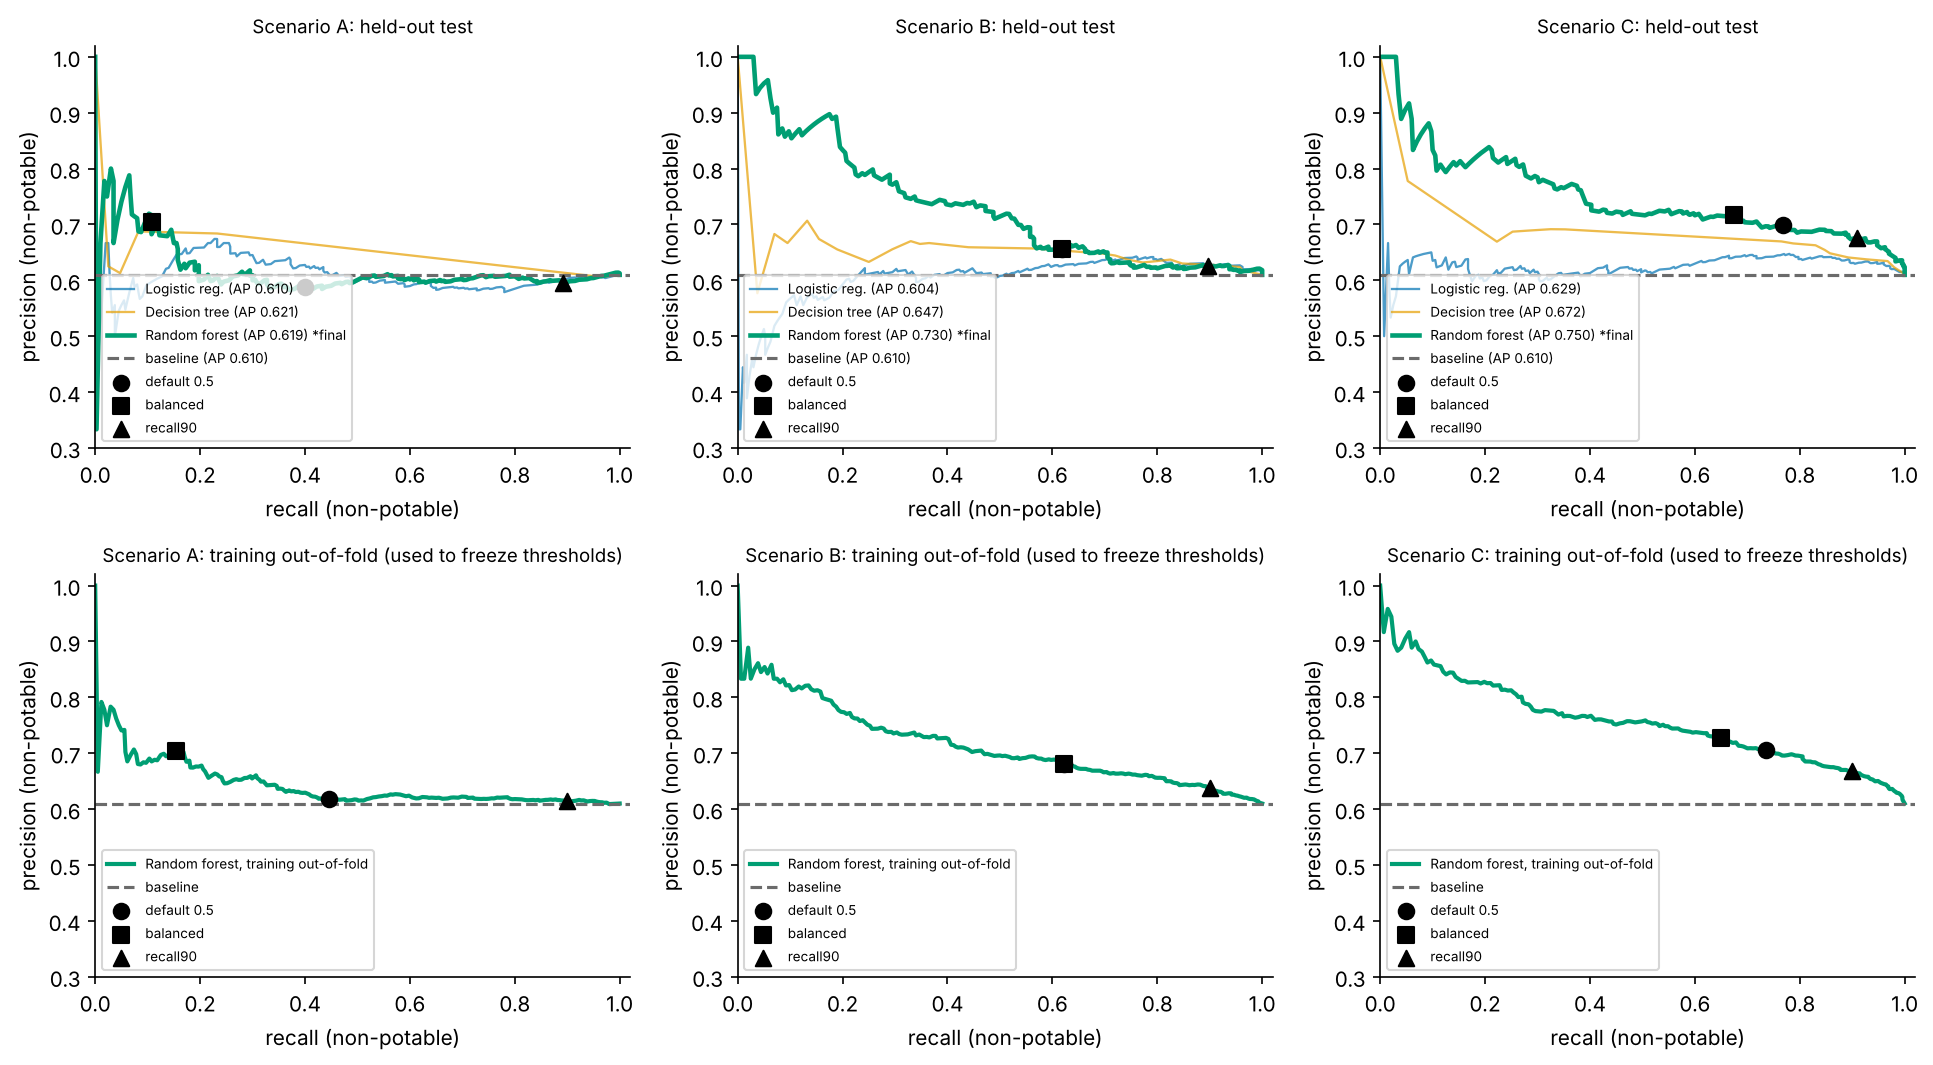

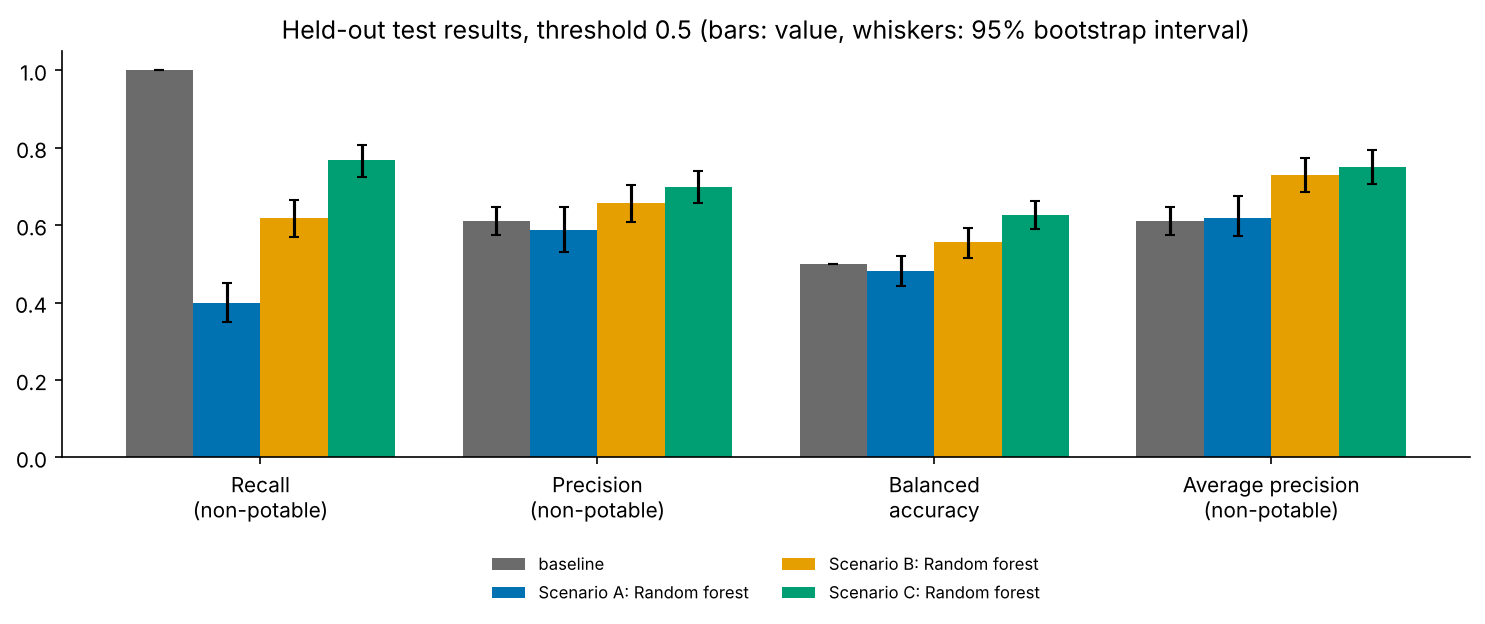

In [20]:
# ---- Experiment 5: precision-recall curves (non-potable = positive), from saved probabilities ----
from sklearn.metrics import precision_recall_curve


def pr_points(is_pos, score, max_pts=220):
    prec, rec, _ = precision_recall_curve(is_pos, score)
    idx = np.unique(np.linspace(0, len(prec) - 1, min(max_pts, len(prec))).round().astype(int))
    return {"recall": np.round(rec[idx], 4).tolist(), "precision": np.round(prec[idx], 4).tolist()}


PR_CURVES = {}
for sc in SCENARIOS:
    is0 = (y_test_arr == 0)
    PR_CURVES[sc] = {
        "test": {fam: pr_points(is0, TEST_P0[(sc, fam)]) for fam in MODEL_FAMS},
        "oof_final": pr_points(y_tr_arr == 0, CVF[(sc, FINAL[sc])]["oof"]),
        "prevalence_test": float(is0.mean()), "prevalence_train": float((y_tr_arr == 0).mean()),
        "ap_test": {fam: POINT[(sc, fam)]["ap_np"] for fam in MODEL_FAMS},
        "operating_points": {r: {"threshold": THRESH[r][sc],
                                 "test_recall": THRESHOLD_ANALYSIS[r][sc]["test"]["recall_np"]["value"],
                                 "test_precision": THRESHOLD_ANALYSIS[r][sc]["test"]["precision_np"]["value"],
                                 "oof_recall": THRESH_INFO[r][sc]["oof_recall_np"], "oof_precision": THRESH_INFO[r][sc]["oof_precision_np"]}
                             for r in RULES},
    }

MK = {"default": ("o", "default 0.5"), "balanced": ("s", "balanced"), "recall90": ("^", "recall90")}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for j, sc in enumerate(SCENARIOS):
    ax = axes[0, j]
    for fam in MODEL_FAMS:
        c = PR_CURVES[sc]["test"][fam]
        ax.plot(c["recall"], c["precision"], color=C_FAM[fam], lw=2.2 if fam == FINAL[sc] else 1.1, alpha=1 if fam == FINAL[sc] else 0.7,
                label=f"{SHORT[fam]} (AP {PR_CURVES[sc]['ap_test'][fam]:.3f})" + (" *final" if fam == FINAL[sc] else ""))
    ax.axhline(PR_CURVES[sc]["prevalence_test"], color=C_BASE, ls="--", label=f"baseline (AP {PR_CURVES[sc]['prevalence_test']:.3f})")
    for r, (m, lab) in MK.items():
        o = PR_CURVES[sc]["operating_points"][r]; ax.scatter(o["test_recall"], o["test_precision"], marker=m, s=55, color="black", zorder=4, label=lab)
    ax.set_xlim(0, 1.02); ax.set_ylim(0.3, 1.02); ax.set_xlabel("recall (non-potable)"); ax.set_ylabel("precision (non-potable)")
    ax.set_title(f"Scenario {sc}: held-out test", fontsize=9); ax.legend(fontsize=6.5, loc="lower left")
    ax = axes[1, j]; c = PR_CURVES[sc]["oof_final"]
    ax.plot(c["recall"], c["precision"], color=C_FAM[FINAL[sc]], lw=2, label=f"{SHORT[FINAL[sc]]}, training out-of-fold")
    ax.axhline(PR_CURVES[sc]["prevalence_train"], color=C_BASE, ls="--", label="baseline")
    for r, (m, lab) in MK.items():
        o = PR_CURVES[sc]["operating_points"][r]; ax.scatter(o["oof_recall"], o["oof_precision"], marker=m, s=55, color="black", zorder=4, label=lab)
    ax.set_xlim(0, 1.02); ax.set_ylim(0.3, 1.02); ax.set_xlabel("recall (non-potable)"); ax.set_ylabel("precision (non-potable)")
    ax.set_title(f"Scenario {sc}: training out-of-fold (used to freeze thresholds)", fontsize=9); ax.legend(fontsize=6.5, loc="lower left")
fig.tight_layout(); save_fig(fig, "pr_curves.png")

# Test summary: final models vs baseline with 95% bootstrap intervals
keys = ["recall_np", "precision_np", "balanced_accuracy", "ap_np"]
fig, ax = plt.subplots(figsize=(10, 4.4))
groups = [("baseline", None, C_BASE)] + [(FINAL[sc], sc, C_SCEN[sc]) for sc in SCENARIOS]
w = 0.2
for j, (fam, sc, col) in enumerate(groups):
    vals, lo, hi = [], [], []
    for k in keys:
        pt = POINT[(sc or "A", fam)][k]
        l, h, _ = pct_ci((BOOT[(sc or "A", fam)])[k])
        vals.append(pt); lo.append(pt - l); hi.append(h - pt)
    xs = np.arange(len(keys)) + (j - 1.5) * w
    ax.bar(xs, vals, w, color=col, label="baseline" if sc is None else f"Scenario {sc}: {NAMES[fam]}", yerr=[lo, hi], capsize=2.5)
ax.set_xticks(range(len(keys))); ax.set_xticklabels(["Recall\n(non-potable)", "Precision\n(non-potable)", "Balanced\naccuracy", "Average precision\n(non-potable)"])
ax.set_ylim(0, 1.05); ax.set_title("Held-out test results, threshold 0.5 (bars: value, whiskers: 95% bootstrap interval)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
fig.tight_layout()
save_fig(fig, "test_summary.png")

## 10. Error analysis

**Why:** one number per metric hides *which* samples go wrong. We look at the confusion matrix of each scenario's final model, a few representative misclassified test samples (the most confident errors plus a few seeded random ones), and whether rows with missing values are handled differently. Confusion-matrix cells use class 0 (non-potable) as the positive class: `tp` = non-potable correctly flagged, `fp` = potable wrongly flagged, `fn` = non-potable wrongly cleared (**the costly false "potable"**), `tn` = potable correctly cleared.

The raw-row tables are controlled by `SHOW_RAW_ROWS` (first cell). Missing values are shown as "missing" (the model itself sees the training median instead).

A forest {'tp': 160, 'fp': 112, 'fn': 240, 'tn': 144}
B forest {'tp': 247, 'fp': 129, 'fn': 153, 'tn': 127}
C forest {'tp': 307, 'fp': 132, 'fn': 93, 'tn': 124}


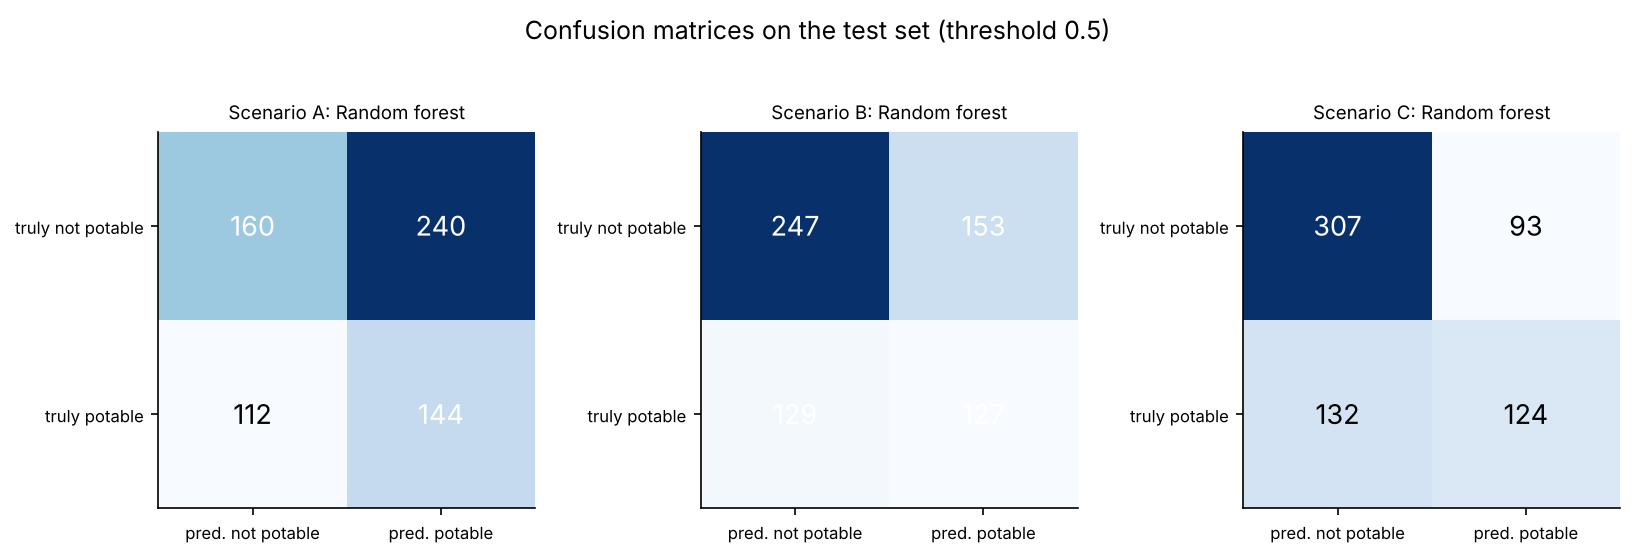

In [21]:
CONFUSION = {k: confusion_counts(y_test_arr, p0) for k, p0 in TEST_P0.items()}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, sc in zip(axes, SCENARIOS):
    c = CONFUSION[(sc, FINAL[sc])]
    mat = np.array([[c["tp"], c["fn"]], [c["fp"], c["tn"]]])
    im = ax.imshow(mat, cmap="Blues")
    for (i, j), v in np.ndenumerate(mat):
        r, g, bl, _ = im.cmap(im.norm(v))  # pick text colour from the cell's actual colour so every number stays readable
        lum = 0.2126 * r + 0.7152 * g + 0.0722 * bl
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color="white" if lum < 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred. not potable", "pred. potable"], fontsize=8)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["truly not potable", "truly potable"], fontsize=8)
    ax.set_title(f"Scenario {sc}: {NAMES[FINAL[sc]]} (final model)", fontsize=9)
fig.suptitle("Confusion matrices on the test set (threshold 0.5)", y=1.02)
fig.tight_layout()
save_fig(fig, "confusion_matrices.png")
for sc in SCENARIOS:
    print(sc, FINAL[sc], CONFUSION[(sc, FINAL[sc])])

In [22]:
# Representative misclassified test samples (final model per scenario, threshold 0.5)
rng_err = np.random.default_rng(SEED)
MISCLASSIFIED = {}


def pick(positions, order_desc, n_conf=3, n_rand=2):
    # positions: array of test positions that are errors; order by confidence, then seeded random extras
    ordered = positions[np.argsort(order_desc)]
    chosen = [(int(p), "most_confident") for p in ordered[:n_conf]]
    rest = ordered[n_conf:]
    if len(rest) > 0:
        extra = rng_err.choice(rest, size=min(n_rand, len(rest)), replace=False)
        chosen += [(int(p), "seeded_random") for p in extra]
    return chosen


for sc in SCENARIOS:
    p0 = TEST_P0[(sc, FINAL[sc])]
    pred0 = p0 >= 0.5
    fp_pos = np.where((y_test_arr == 0) & ~pred0)[0]       # false "potable": true 0, predicted 1
    fn_pos = np.where((y_test_arr == 1) & pred0)[0]        # false "non-potable": true 1, predicted 0
    items = []
    for kind, positions, key in [("false_potable", fp_pos, p0[fp_pos]),          # most confident = lowest p0
                                 ("false_nonpotable", fn_pos, -p0[fn_pos])]:     # most confident = highest p0
        for pos, how in pick(positions, key):
            feats_raw = None
            if SHOW_RAW_ROWS:
                row = X_test.iloc[pos]
                feats_raw = {f: ("missing" if pd.isna(row[f]) else float(row[f])) for f in FEATURES}
            items.append({"row_index": int(TEST_IDX[pos]), "type": kind, "selection": how,
                          "true_label": int(y_test_arr[pos]), "predicted_label": 0 if pred0[pos] else 1,
                          "p_nonpotable": float(p0[pos]), "features": feats_raw})
    MISCLASSIFIED[sc] = items

if SHOW_RAW_ROWS:
    for sc in SCENARIOS:
        print(f"\n=== Scenario {sc} ({FINAL[sc]}); features used: {SCENARIOS[sc]['features']} ===")
        t = pd.DataFrame([{"row": m["row_index"], "type": m["type"], "how": m["selection"], "p(non-potable)": round(m["p_nonpotable"], 3),
                           **{f: (m["features"][f] if m["features"][f] == "missing" else round(m["features"][f], 2)) for f in FEATURES}}
                          for m in MISCLASSIFIED[sc]])
        print(t.to_string(index=False))
else:
    print("SHOW_RAW_ROWS is False: raw feature values are hidden (row index, labels and probabilities are kept).")


=== Scenario A (forest); features used: ['ph', 'Conductivity', 'Turbidity'] ===
 row             type            how  p(non-potable)      ph  Hardness   Solids  Chloramines Sulfate  Conductivity  Organic_carbon  Trihalomethanes  Turbidity
2121    false_potable most_confident           0.423    6.95    214.17 32946.57         5.48  333.44        318.88           12.81            15.68       4.93
 539    false_potable most_confident           0.429 missing    204.92 12556.75         5.79  359.95        610.77           16.01            52.44       3.26
2091    false_potable most_confident           0.429    7.25    223.70 24311.91         7.39  275.62        306.78            9.70            77.20       4.36
2279    false_potable  seeded_random           0.450    7.54    201.96 26716.36         5.64 missing        516.35           14.99            83.54       4.21
2544    false_potable  seeded_random           0.493    7.05    212.43  7450.07         8.73 missing        396.05          

In [23]:
# Error rates for rows WITH vs WITHOUT missing values in the features the scenario uses
MISSING_ANALYSIS = {}
for sc in SCENARIOS:
    feats = SCENARIOS[sc]["features"]
    has_missing = X_test[feats].isna().any(axis=1).to_numpy()
    p0 = TEST_P0[(sc, FINAL[sc])]; pred0 = p0 >= 0.5
    out = {}
    for name, mask in [("with_missing", has_missing), ("without_missing", ~has_missing)]:
        yt, pr = y_test_arr[mask], pred0[mask]
        n0, n1 = int((yt == 0).sum()), int((yt == 1).sum())
        out[name] = {"n_rows": int(mask.sum()), "n_nonpotable": n0, "n_potable": n1,
                     "false_potable_rate": float(((yt == 0) & ~pr).sum() / n0) if n0 else None,       # share of truly non-potable called potable
                     "false_nonpotable_rate": float(((yt == 1) & pr).sum() / n1) if n1 else None,     # share of truly potable called non-potable
                     "error_rate": float(((yt == 0) != pr).sum() / len(yt)) if len(yt) else None}
    MISSING_ANALYSIS[sc] = out
    w_, wo = out["with_missing"], out["without_missing"]
    fmt = lambda v: "n/a" if v is None else f"{v:.3f}"
    print(f"Scenario {sc}: rows with missing {w_['n_rows']} vs without {wo['n_rows']} | share of truly non-potable called potable: "
          f"{fmt(w_['false_potable_rate'])} vs {fmt(wo['false_potable_rate'])} | overall error rate: {fmt(w_['error_rate'])} vs {fmt(wo['error_rate'])}")
print("\nSmall groups give noisy rates; read these as descriptive, not as a finding.")

Scenario A: rows with missing 104 vs without 552 | share of truly non-potable called potable: 0.515 vs 0.617 | overall error rate: 0.500 vs 0.543
Scenario B: rows with missing 104 vs without 552 | share of truly non-potable called potable: 0.544 vs 0.349 | overall error rate: 0.510 vs 0.415
Scenario C: rows with missing 252 vs without 404 | share of truly non-potable called potable: 0.241 vs 0.227 | overall error rate: 0.385 vs 0.317

Small groups give noisy rates; read these as descriptive, not as a finding.


## 11. Limitations

- **No safety claim.** We do **not** claim that a sample predicted "potable" is safe to drink. The dataset has no microbial or heavy-metal measurements, and how the label was produced is unclear.
- **Association, not cause.** Models find patterns in this one file; feature importance or model coefficients would not prove that any measurement causes potability, and we do not read them that way.
- **Scenarios are experimental feature subsets**, not validated testing procedures. The A/B grouping is our assumption, not a property of the data.
- **No generalisation; synthetic source.** Kaggle's metadata lists the data's provenance as "Synthetically generated", so results describe this dataset, not real water samples. Results must not be generalised to Indian rivers or any specific region.
- **Single split.** One 80/20 split and one seed; hyperparameters were chosen by cross-validation on the training part, and the bootstrap intervals do not capture that selection uncertainty or split-to-split variation.
- **Imputation.** Median imputation is simple; roughly a fifth of `Sulfate` and a seventh of `ph` values are missing, and missingness could itself be informative (not tested here).
- **Thresholds are a trade-off, not a free gain.** The three frozen operating points were chosen on training data; a stricter threshold lowers the share of wrong "potable" calls but clears far fewer potable samples.
- **Test set.** Model, class-weight, indicator and threshold choices used cross-validation on the training part only; the 20% hold-out set scores the final models. Cross-validation and test scores agree closely.
- **Greedy, staged tuning.** Structure, class weights and indicators were tuned one after another, not jointly; CV scores of tuned settings are slightly optimistic because the same folds chose them.
- **Dataset licence.** The Kaggle page lists the licence as CC0: Public Domain. The CSV is included in `data/` for convenience.

## 12. Export

**Why:** the website reads every number from `docs/results.json`, so nothing on the page is typed by hand. The JSON is written with `allow_nan=False` so it is always valid for `fetch()`; undefined values (for example precision for the baseline's potable calls) are stored as `null`.

In [24]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (np.floating, float)):
        v = float(o)
        return None if (math.isnan(v) or math.isinf(v)) else v
    return o


def versions():
    out = {"python": platform.python_version()}
    for pkg in ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib", "jupyter", "nbconvert", "ipykernel"]:
        try:
            out[pkg] = md.version(pkg)
        except md.PackageNotFoundError:
            out[pkg] = "not installed in the environment that produced these results"
    return out


short = lambda d: {k.replace("clf__", ""): v for k, v in d.items()}


def params_for_json(sc, fam):
    if fam == "baseline":
        return {"strategy": "most_frequent"}
    cfg = FINAL_CFG[(sc, fam)]
    return {**short(cfg["params"]), "class_weight": cfg["cw_name"], "missing_indicator": cfg["indicator"]}


def tuning_info(sc, fam):
    i, c = STAGE1_PICK[(sc, fam)], CW_INFO[(sc, fam)]
    return {"stage1_best_by_mean_params": short(i["best_params"]), "stage1_best_by_mean_cv_ap": i["best_mean"], "stage1_best_by_mean_gap": i["best_gap"],
            "stage1_chosen_cv_ap": i["chosen_mean"], "stage1_chosen_gap": i["chosen_gap"], "stage1_se_best": i["se_best"],
            "stage1_eligible_settings": i["n_candidates"], "stage1_total_settings": i["n_settings"],
            "class_weight_chosen": c["chosen"], "class_weight_best_by_ap": c["best_by_ap"], "class_weight_eligible": c["eligible"],
            "missing_indicator": IND_INFO[(sc, fam)]}


scenarios_out = {}
for sc, spec in SCENARIOS.items():
    models = {}
    for fam in FAMILIES:
        models[fam] = {"name": NAMES[fam], "is_final": bool(fam == FINAL[sc]),
                       "cv": CV[(sc, fam)]["cv"], "cv_ap_folds": CV[(sc, fam)]["ap_folds"],
                       "cv_train_vs_val": CV[(sc, fam)]["cv_train_vs_val"],
                       "test": test_block(POINT[(sc, fam)], BOOT[(sc, fam)]),
                       "confusion": CONFUSION[(sc, fam)], "best_params": params_for_json(sc, fam),
                       "tuning": None if fam == "baseline" else tuning_info(sc, fam)}
    scenarios_out[sc] = {"label": spec["label"], "features": spec["features"], "new_features": spec["new_features"],
                         "n_features": len(spec["features"]), "models": models, "final_model": FINAL[sc],
                         "selection": SELECTION[sc], "missing_error_analysis": MISSING_ANALYSIS[sc]}

experiments = {
    "rf_tuning": {sc: {"grid": STAGE1_PICK[(sc, "forest")]["rows"], "grid_spec": {k.replace("clf__", ""): v for k, v in STAGE1["forest"].items()},
                       "tuned_params": params_for_json(sc, "forest"), "tuned_cv_ap": CV[(sc, "forest")]["cv"]["ap_np"]["mean"],
                       "tuned_gap": CV[(sc, "forest")]["cv_train_vs_val"]["gap"]} for sc in SCENARIOS},
    "class_weight": {sc: {fam: {"options": {n: {"cv_ap": mean_std(r["val"]["ap_np"]), "recall_np": mean_std(r["val"]["recall_np"]),
                                                  "precision_np": mean_std(r["val"]["precision_np"]), "recall_p": mean_std(r["val"]["recall_p"]),
                                                  "false_potable_share": mean_std(r["val"]["false_potable_share"]),
                                                  "balanced_accuracy": mean_std(r["val"]["balanced_accuracy"])}
                                              for n, r in CW_RES[(sc, fam)].items()},
                              "chosen": CW_INFO[(sc, fam)]["chosen"], "best_by_ap": CW_INFO[(sc, fam)]["best_by_ap"],
                              "eligible": CW_INFO[(sc, fam)]["eligible"], "se_best": CW_INFO[(sc, fam)]["se_best"]}
                          for fam in MODEL_FAMS} for sc in SCENARIOS},
    "threshold": {sc: {"sweep": OOF_SWEEP[sc], "model": FINAL[sc]} for sc in SCENARIOS},
    "missing_indicator": {sc: {fam: IND_INFO[(sc, fam)] for fam in MODEL_FAMS} for sc in SCENARIOS},
    "pr_curves": PR_CURVES,
}

results = {
    "meta": {
        "title": "Screening Water Samples for Potability: A Baseline-Driven Classification Study",
        "version": "final",
        "test_set_note": "Model selection used 5-fold cross-validation on the training part only; the 20% hold-out set scores the final models. Cross-validation and test scores agree closely.",
        "seed": SEED, "n_rows": int(len(df)), "n_train": int(len(X_train)), "n_test": int(n_test),
        "class_counts": {"0": int(vc[0]), "1": int(vc[1])},
        "class_share": {"0": float(vc[0] / len(df)), "1": float(vc[1] / len(df))},
        "split": {"test_size": 0.2, "stratified": True, "cv_folds": 5, "cv_shuffle": True,
                  "train_class_counts": {"0": int((y_train == 0).sum()), "1": int((y_train == 1).sum())},
                  "test_class_counts": {"0": int((y_test_arr == 0).sum()), "1": int((y_test_arr == 1).sum())}},
        "missing_counts": {f: int(df[f].isna().sum()) for f in FEATURES},
        "date": datetime.date.today().isoformat(),
        "package_versions": versions(),
        "executed_via": os.environ.get("EXECUTED_VIA", "jupyter kernel (nbconvert --execute)"),
        "n_bootstrap": N_BOOT, "ci_level": 0.95, "default_threshold": 0.5,
        "rules": RULES, "rule_text": RULE_TEXT,
        "metric_labels": METRIC_LABELS, "show_raw_rows": bool(SHOW_RAW_ROWS),
        "stage1_grids": {fam: {k.replace("clf__", ""): v for k, v in g.items()} for fam, g in STAGE1.items()},
        "class_weight_options": {n: (c if not isinstance(c, dict) else {str(k): v for k, v in c.items()}) for n, c in CW_LOOKUP.items()},
    },
    "data_summary": {
        "group_means": {f: {"0": float(group_means.loc[f].iloc[0]), "1": float(group_means.loc[f].iloc[1])} for f in FEATURES},
        "missing_pct": {f: float(100 * df[f].isna().mean()) for f in FEATURES},
        "note": "Descriptive, computed on all 3,276 rows; no modelling choice used it.",
    },
    "scenarios": scenarios_out,
    "differences": {"final_vs_baseline": DIFF_FINAL_VS_BASE, **DIFF_FINAL_SCEN},
    "differences_same_family": DIFF_SAME_FAMILY,
    "threshold_analysis": THRESHOLD_ANALYSIS,
    "experiments": experiments,
    "misclassified": MISCLASSIFIED,
}
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(RESULTS_PATH, "w") as fh:
    json.dump(clean(results), fh, indent=1, allow_nan=False)
print("Wrote", RESULTS_PATH, f"({RESULTS_PATH.stat().st_size / 1024:.0f} KB)")
print("Plots in", ASSETS, ":", sorted(p.name for p in ASSETS.glob("*.png")))

Wrote /home/claude/docs/results.json (242 KB)
Plots in /home/claude/docs/assets : ['class_balance.png', 'class_weight.png', 'confusion_matrices.png', 'cv_results.png', 'feature_distributions.png', 'missing_indicators.png', 'missingness.png', 'pr_curves.png', 'rf_tuning.png', 'test_summary.png', 'threshold_tradeoff.png']


In [25]:
# ---- Final quality checks on the exported file ----
chk = json.load(open(RESULTS_PATH))
assert chk["meta"]["n_rows"] == 3276 and chk["meta"]["n_train"] + chk["meta"]["n_test"] == 3276
for sc in "ABC":
    s = chk["scenarios"][sc]
    assert set(s["models"]) == {"baseline", "logreg", "tree", "forest"} and s["final_model"] in {"logreg", "tree", "forest"}
    b = s["models"]["baseline"]["test"]
    assert b["recall_np"]["value"] == 1.0 and abs(b["balanced_accuracy"]["value"] - 0.5) < 1e-12
    assert b["precision_p"]["value"] is None and b["false_potable_share"]["value"] is None
    assert abs(b["ap_np"]["value"] - chk["meta"]["split"]["test_class_counts"]["0"] / chk["meta"]["n_test"]) < 1e-12
    for fam, m in s["models"].items():
        c = m["confusion"]
        assert c["tp"] + c["fn"] == chk["meta"]["split"]["test_class_counts"]["0"]
        assert c["fp"] + c["tn"] == chk["meta"]["split"]["test_class_counts"]["1"]
    assert set(chk["threshold_analysis"]) == {"default", "balanced", "recall90"}
print("results.json checks passed (baseline: recall 1.0, balanced accuracy 0.5, precision(potable) null, AP = class-0 share.")
print("Final models:", {sc: chk["scenarios"][sc]["final_model"] for sc in "ABC"})

results.json checks passed (baseline: recall 1.0, balanced accuracy 0.5, precision(potable) null, AP = class-0 share.
Final models: {'A': 'forest', 'B': 'forest', 'C': 'forest'}
